In [1]:
from __future__ import print_function
import sys, os
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from collections import defaultdict
import multiprocessing

import ROOT
from ROOT import gROOT, gStyle, gDirectory, gPad
nthreads = min(4, max(1, multiprocessing.cpu_count()-1))  # tune as needed
ROOT.EnableImplicitMT(nthreads)

ROOT.gStyle.SetPalette(57)
ROOT.gStyle.SetNumberContours(255)

import constants


In [2]:
# POTs for resampler 
nPOT = 1.0e12

VDresampler_dict = {
    'Ele_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },
}

# MC truth of upstream dataset to VD101
MCTruth_dict = {
    "Ele_Beam1a":{
        "file": "tmp/ele101_MDC2025ai_dump.root",
        "POTs": 98360017778.32725, # dts.mu2e.STMBeamToVDEle116.MDC2025ai.art    : 5441845688 / 5532579  * 1e8
    },
    "Mu_Beam1a":{
        "file": "tmp/mu101_MDC2025ai_dump2.root",
        "POTs": 467691847195.7197, # dts.mu2e.STMBeamToVDMu116.MDC2025ai.art     : 1e9        / 213816   * 1e8
    },
    "1809_Beam1a":{
         "file": "tmp/tgtstps101_MDC2025au_dump.root",
        "POTs": 5186958594225.648, # dts.mu2e.STM1809ToVD116.MDC2025au.art       : 4e9     / 1442670/1e3 * 4e9 / 213816  * 1e8
    },
    "Neutrals_Beam1a":{
        "file": "tmp/neutrals101_MDC2025av_dump.root",
        "POTs": 3743491962.619810  # dts.mu2e.STMNeutralsToVD116Cat.MDC2025av.art: 2000000000 / 53426053 * 1e8
    },
}

In [3]:
# back-extrapolate from VD101 (z1) to z0 along the momentum direction
Z0_EXTRAP = 37700.39
BEAM1ACUT_R = 2000.

BEAM1ACUT_EXPR = (
    f"pz > 0 && "
    f"( pow(x + px/pz*({Z0_EXTRAP} - {constants.VD101_Z}) - ({constants.VD101_X}), 2)"
    f"+ pow(y + py/pz*({Z0_EXTRAP} - {constants.VD101_Z}), 2) )"
    f" < {BEAM1ACUT_R**2}"
)

In [4]:
pdg_groups = {
    "e-"      : 11,
    "gamma"   : 22,
    "e+"      : -11,
    "neutron" : 2112,
}
pdg_colors = {
    "e-"      : ROOT.kRed + 1,
    "gamma"   : ROOT.kOrange + 1,
    "e+"      : ROOT.kBlue + 1,
    "neutron" : ROOT.kGreen + 2,
    "other"   : ROOT.kGray + 1,
}
campaign_order = [
    "Beam1a",
    "Beam1aCut",
    "stmedep00",
    "stmedep01",
    "stmedep02",
    "stmedep03",
    "stmedep04",
]
campaign_colors = {
    "Beam1a"   : ROOT.kBlack,
    "Beam1aCut": ROOT.kGray + 2,
    "stmedep00": ROOT.kRed+1,
    "stmedep01": ROOT.kBlue+1,
    "stmedep02": ROOT.kGreen+2,
    "stmedep03": ROOT.kOrange+7,
    "stmedep04": ROOT.kMagenta+1,
}
# --------------------------------------------------
# Merge dictionaries
# --------------------------------------------------
samples = {}
samples.update(VDresampler_dict)
samples.update(MCTruth_dict)
# --------------------------------------------------
# Categorize samples
# --------------------------------------------------
categories = ["Ele", "Mu", "1809", "Neutrals"]
sample_groups = defaultdict(dict)
for name, info in samples.items():
    for cat in categories:
        if name.startswith(cat):
            sample_groups[cat][name] = info
            break
# --------------------------------------------------
# normalization
# --------------------------------------------------
target_POT = {}
norm_weights = {}
for cat in categories:
    targetPOT = min(
        sample_groups[cat][s]["POTs"]
        for s in sample_groups[cat]
    )
    target_POT[cat] = targetPOT
    print(cat, "target POT =", targetPOT)
    for s in sample_groups[cat]:
        norm_weights[s] = (targetPOT / sample_groups[cat][s]["POTs"])
        print(f"  {s:20s}", f"weight={norm_weights[s]:.5g}")

Ele target POT = 98360017778.32726
  Ele_stmedep00        weight=0.09836
  Ele_stmedep01        weight=0.09836
  Ele_stmedep02        weight=0.09836
  Ele_stmedep03        weight=0.09836
  Ele_stmedep04        weight=0.09836
  Ele_Beam1a           weight=1
Mu target POT = 467691847195.7197
  Mu_stmedep00         weight=0.46769
  Mu_stmedep01         weight=0.46769
  Mu_stmedep02         weight=0.46769
  Mu_stmedep03         weight=0.46769
  Mu_stmedep04         weight=0.46769
  Mu_Beam1a            weight=1
1809 target POT = 1000000000000.0
  1809_stmedep00       weight=1
  1809_stmedep01       weight=1
  1809_stmedep02       weight=1
  1809_stmedep03       weight=1
  1809_stmedep04       weight=1
  1809_Beam1a          weight=0.19279
Neutrals target POT = 3743491962.61981
  Neutrals_stmedep00   weight=0.0037435
  Neutrals_stmedep01   weight=0.0037435
  Neutrals_stmedep02   weight=0.0037435
  Neutrals_stmedep03   weight=0.0037435
  Neutrals_stmedep04   weight=0.0037435
  Neutrals_Beam1

In [5]:
def draw_pdg_composition(category):

    stack = ROOT.THStack(f"stack_{category}", f"Particles from {category} source;Campaign;Normalized counts to {target_POT[category]:.2e} POTs")

    # one histogram per PDG species
    hist_dict = {}

    for name in list(pdg_groups.keys()) + ["other"]:

        h = ROOT.TH1D(f"h_{category}_{name}", "", len(campaign_order), 0, len(campaign_order))
        h.SetDirectory(0)          # do not let a TFile own/delete it
        ROOT.SetOwnership(h, False)  # do not let Python delete it on return
        for i, camp in enumerate(campaign_order, start=1):
            h.GetXaxis().SetBinLabel(i, camp)

        h.SetFillColor(pdg_colors[name])
        h.SetLineColor(ROOT.kBlack)

        hist_dict[name] = h

    # ------------------------------------
    # fill campaign bins
    # ------------------------------------

    for ibin, campaign in enumerate(campaign_order, start=1):

        # Beam1aCut reuses the Beam1a sample with an extra acceptance cut
        is_cut = campaign.endswith("Cut")
        base_campaign = campaign[:-3] if is_cut else campaign
        sample = f"{category}_{base_campaign}"

        if sample not in sample_groups[category]:
            print(f"Missing sample: {sample}")
            continue

        df = (ROOT.RDataFrame("Stage1virtualdetector/ttree",
                              sample_groups[category][sample]["file"])
              .Filter("pz > 0"))
        if is_cut:
            df = df.Filter(BEAM1ACUT_EXPR)

        weight = norm_weights[sample]

        known_expr = []    
        for label, pdg in pdg_groups.items():
            n = (df.Filter(f"pdgId == {pdg}").Count().GetValue())
            print(f"{campaign:20s}", f"{label:8s}", f"{n:10d}", f"{n*weight:10.0f}")

            hist_dict[label].SetBinContent(ibin,n * weight)
            hist_dict[label].SetBinError(ibin,(n**0.5) * weight)

            known_expr.append(f"pdgId == {pdg}")

        other_cut = "!(" + " || ".join(known_expr) + ")"

        n_other = (df.Filter(other_cut).Count().GetValue())
        hist_dict["other"].SetBinContent(ibin,n_other * weight)
        hist_dict["other"].SetBinError(ibin,(n_other**0.5) * weight)
        print("---")

    # ------------------------------------
    # draw
    # ------------------------------------

    # order of stacking
    stack_order = ["gamma","e-","e+","neutron","other"]

    for name in stack_order:
        stack.Add(hist_dict[name])

    c = ROOT.TCanvas(f"c_{category}", category, 1200, 800)
    c.cd()                      # make sure this canvas is current
    c.SetRightMargin(0.22)
    c.SetGridy()

    stack.Draw("hist")
    c.Update()                  # frame now exists with the margin applied

    legend = ROOT.TLegend(0.79, 0.55, 0.97, 0.88)
    for name in stack_order:
        legend.AddEntry(hist_dict[name], name, "f")
    legend.SetBorderSize(0)
    legend.SetFillStyle(0)
    legend.SetTextSize(0.03)
    legend.Draw()

    c._keep = (stack, legend, hist_dict)
    c.Modified()
    c.Update()

    return c

In [6]:
def draw_spectra_comparison(category,
                            campaigns=("Beam1a", "Beam1aCut", "stmedep00"),
                            nbins=50,
                            ranges=None):
    """Overlay kinetic-energy, pz and transverse-momentum spectra for two
    campaigns of one category, split by PDG species. Returns the canvas."""

    species = list(pdg_groups.keys())          # e-, gamma, e+, neutron

    # variable name -> (RDF expression, axis title)
    variables = {
        "E"  : ("E",                    "Kinetic energy [MeV]"),
        "pz" : ("pz",                   "p_{z} [MeV/c]"),
        "pt" : ("sqrt(px*px + py*py)",  "p_{T} [MeV/c]"),
    }

    # axis ranges: override per variable via `ranges`, else these defaults
    default_ranges = {"E": (0., 20.), "pz": (0., 20.), "pt": (0., 10.)}
    if ranges:
        default_ranges.update(ranges)

    camp_colors = {
        "Beam1a"   : ROOT.kBlack,
        "Beam1aCut": ROOT.kAzure + 1,
        "stmedep00": ROOT.kRed + 1,
    }

    # ------------------------------------
    # book and fill
    # ------------------------------------
    hist_dict = {}   # (campaign, species, varname) -> TH1D

    for campaign in campaigns:
        is_cut = campaign.endswith("Cut")
        base_campaign = campaign[:-3] if is_cut else campaign
        sample = f"{category}_{base_campaign}"

        if sample not in sample_groups[category]:
            print(f"Missing sample: {sample}")
            continue

        df = (ROOT.RDataFrame("Stage1virtualdetector/ttree",
                              sample_groups[category][sample]["file"])
              .Filter("pz > 0"))
        if is_cut:
            df = df.Filter(BEAM1ACUT_EXPR)

        weight = norm_weights[sample]

        # book everything first so RDataFrame fills in one event loop
        booked = {}
        for sp in species:
            dsp = df.Filter(f"pdgId == {pdg_groups[sp]}")
            for var, (expr, _) in variables.items():
                lo, hi = default_ranges[var]
                name = f"h_{category}_{campaign}_{sp}_{var}"
                booked[(sp, var)] = dsp.Define(f"v_{var}", expr).Histo1D(
                    (name, "", nbins, lo, hi), f"v_{var}")
                booked[(sp, var)].SetStats(0)

        for (sp, var), ptr in booked.items():
            h = ptr.GetValue().Clone()     # detach from the RDF result
            h.SetDirectory(0)
            ROOT.SetOwnership(h, False)
            h.Scale(weight)                # POT normalization
            h.SetLineColor(camp_colors[campaign])
            h.SetLineWidth(1)
            if campaign == "Beam1a":
                h.SetLineWidth(2)
            h.SetMarkerColor(camp_colors[campaign])
            hist_dict[(campaign, sp, var)] = h

    # ------------------------------------
    # draw: rows = species, columns = E / pz / pt
    # ------------------------------------
    c = ROOT.TCanvas(f"c_spec_{category}", f"{category} spectra", 1800, 1600)
    c.Divide(len(variables), len(species))

    keep = []
    for irow, sp in enumerate(species):
        for icol, (var, (_, xtitle)) in enumerate(variables.items()):

            pad = c.cd(irow * len(variables) + icol + 1)
            pad.SetLogy()
            pad.SetRightMargin(0.04)
            pad.SetLeftMargin(0.14)

            present = [cp for cp in campaigns if (cp, sp, var) in hist_dict]
            hists = [hist_dict[(cp, sp, var)] for cp in present]
            if not hists:
                continue

            # draw the taller one first so neither is clipped
            ymax = max(h.GetMaximum() for h in hists)
            for i, h in enumerate(hists):
                h.SetTitle(f"{sp} {var};{xtitle};Normalized counts")
                h.GetYaxis().SetTitleOffset(1.6)
                h.SetMaximum(ymax * 5.)
                h.SetMinimum(max(1e-2, ymax * 1e-6))
                h.Draw("hist e" if i == 0 else "hist e same")

            leg = ROOT.TLegend(0.62, 0.70, 0.95, 0.90)
            leg.SetBorderSize(0)
            leg.SetFillStyle(0)
            leg.SetTextSize(0.04)
            for cp, h in zip(present, hists):
                leg.AddEntry(h, f"{cp} ({h.Integral():.3g})", "l")
            leg.Draw()
            keep.append(leg)

    c._keep = (hist_dict, keep)
    c.Modified()
    c.Update()

    return c


Beam1a               e-             4491       4491
Beam1a               gamma         32318      32318
Beam1a               e+               87         87
Beam1a               neutron          15         15
---
Beam1aCut            e-             3830       3830
Beam1aCut            gamma         29316      29316
Beam1aCut            e+               68         68
Beam1aCut            neutron           8          8
---
stmedep00            e-            30902       3040
stmedep00            gamma        275812      27129
stmedep00            e+              694         68
stmedep00            neutron          58          6
---
stmedep01            e-            30898       3039
stmedep01            gamma        275808      27128
stmedep01            e+              694         68
stmedep01            neutron          58          6
---
stmedep02            e-            30900       3039
stmedep02            gamma        275804      27128
stmedep02            e+              694        

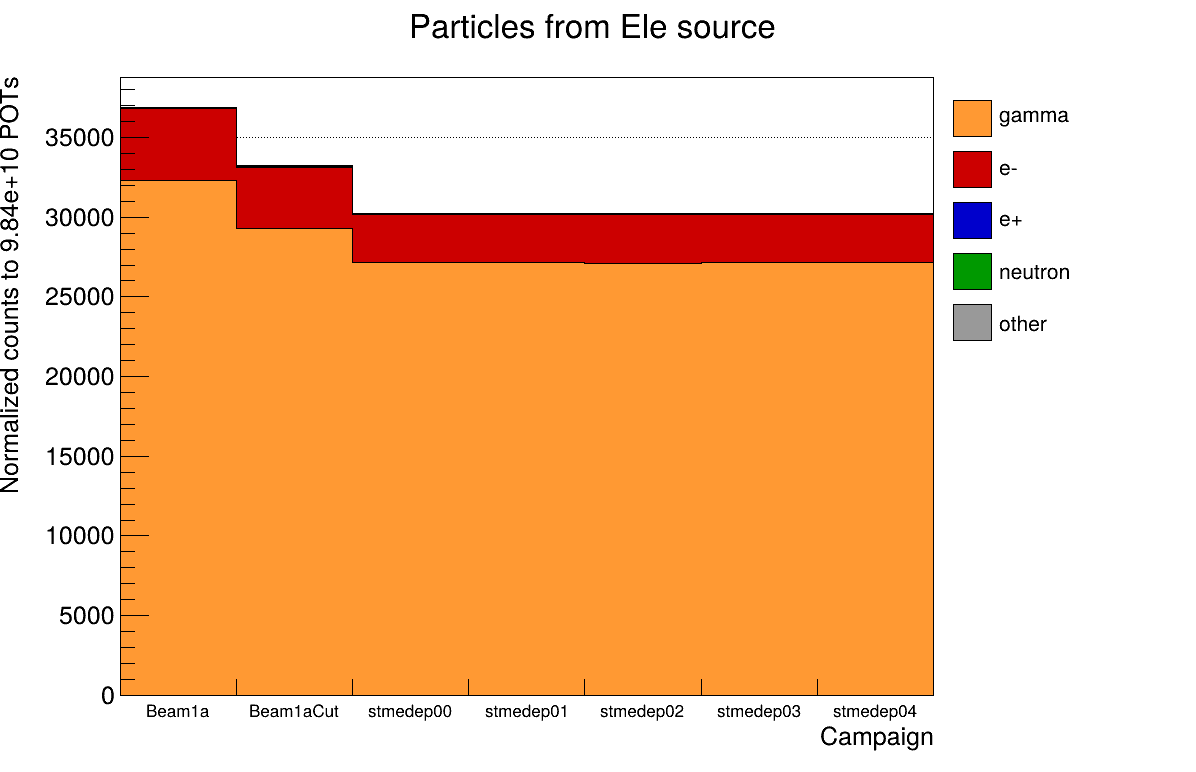

In [7]:
c = draw_pdg_composition("Ele")
c.Draw()

Above behavior is a known deficit. 
gamma: 27129/32318 = 0.84
We know from VD Resampler diagnostics that there is a ~20% lower amount of gamma in the center
e-: 3040/4491 = 0.68, and e- does have a deficit in the center too

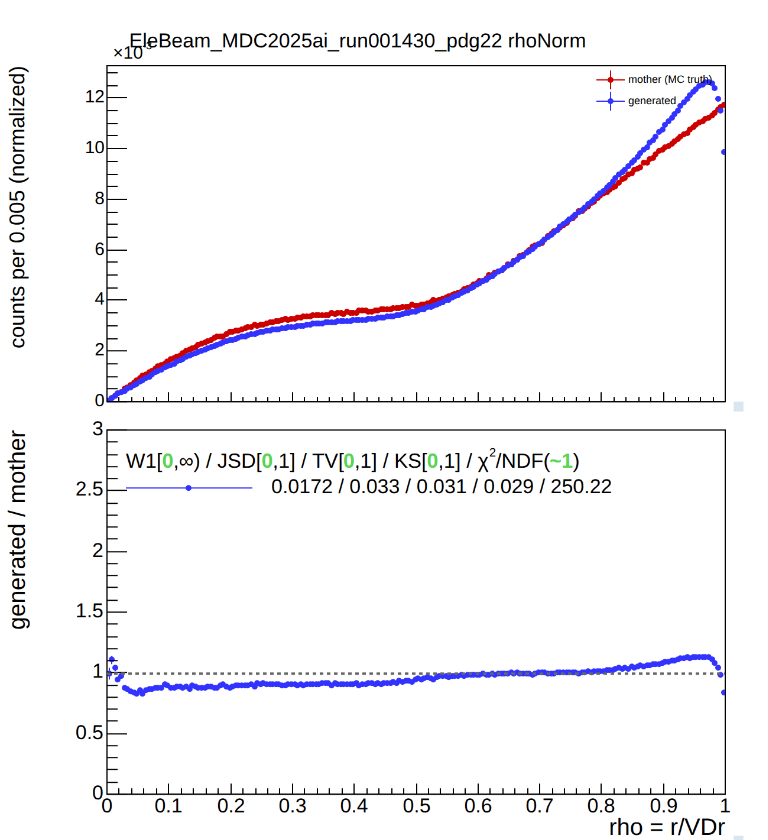
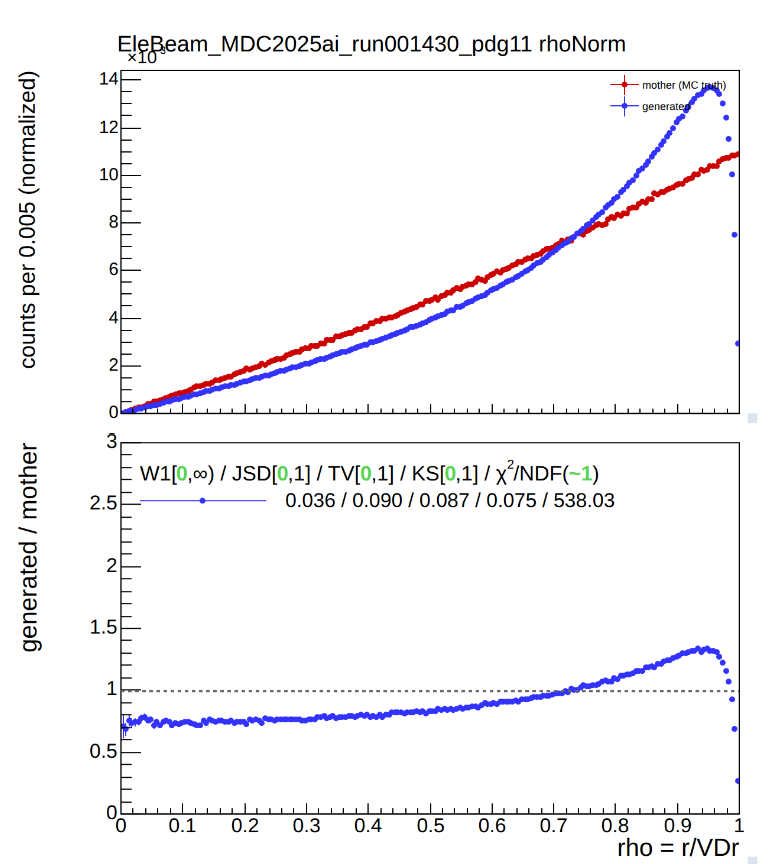


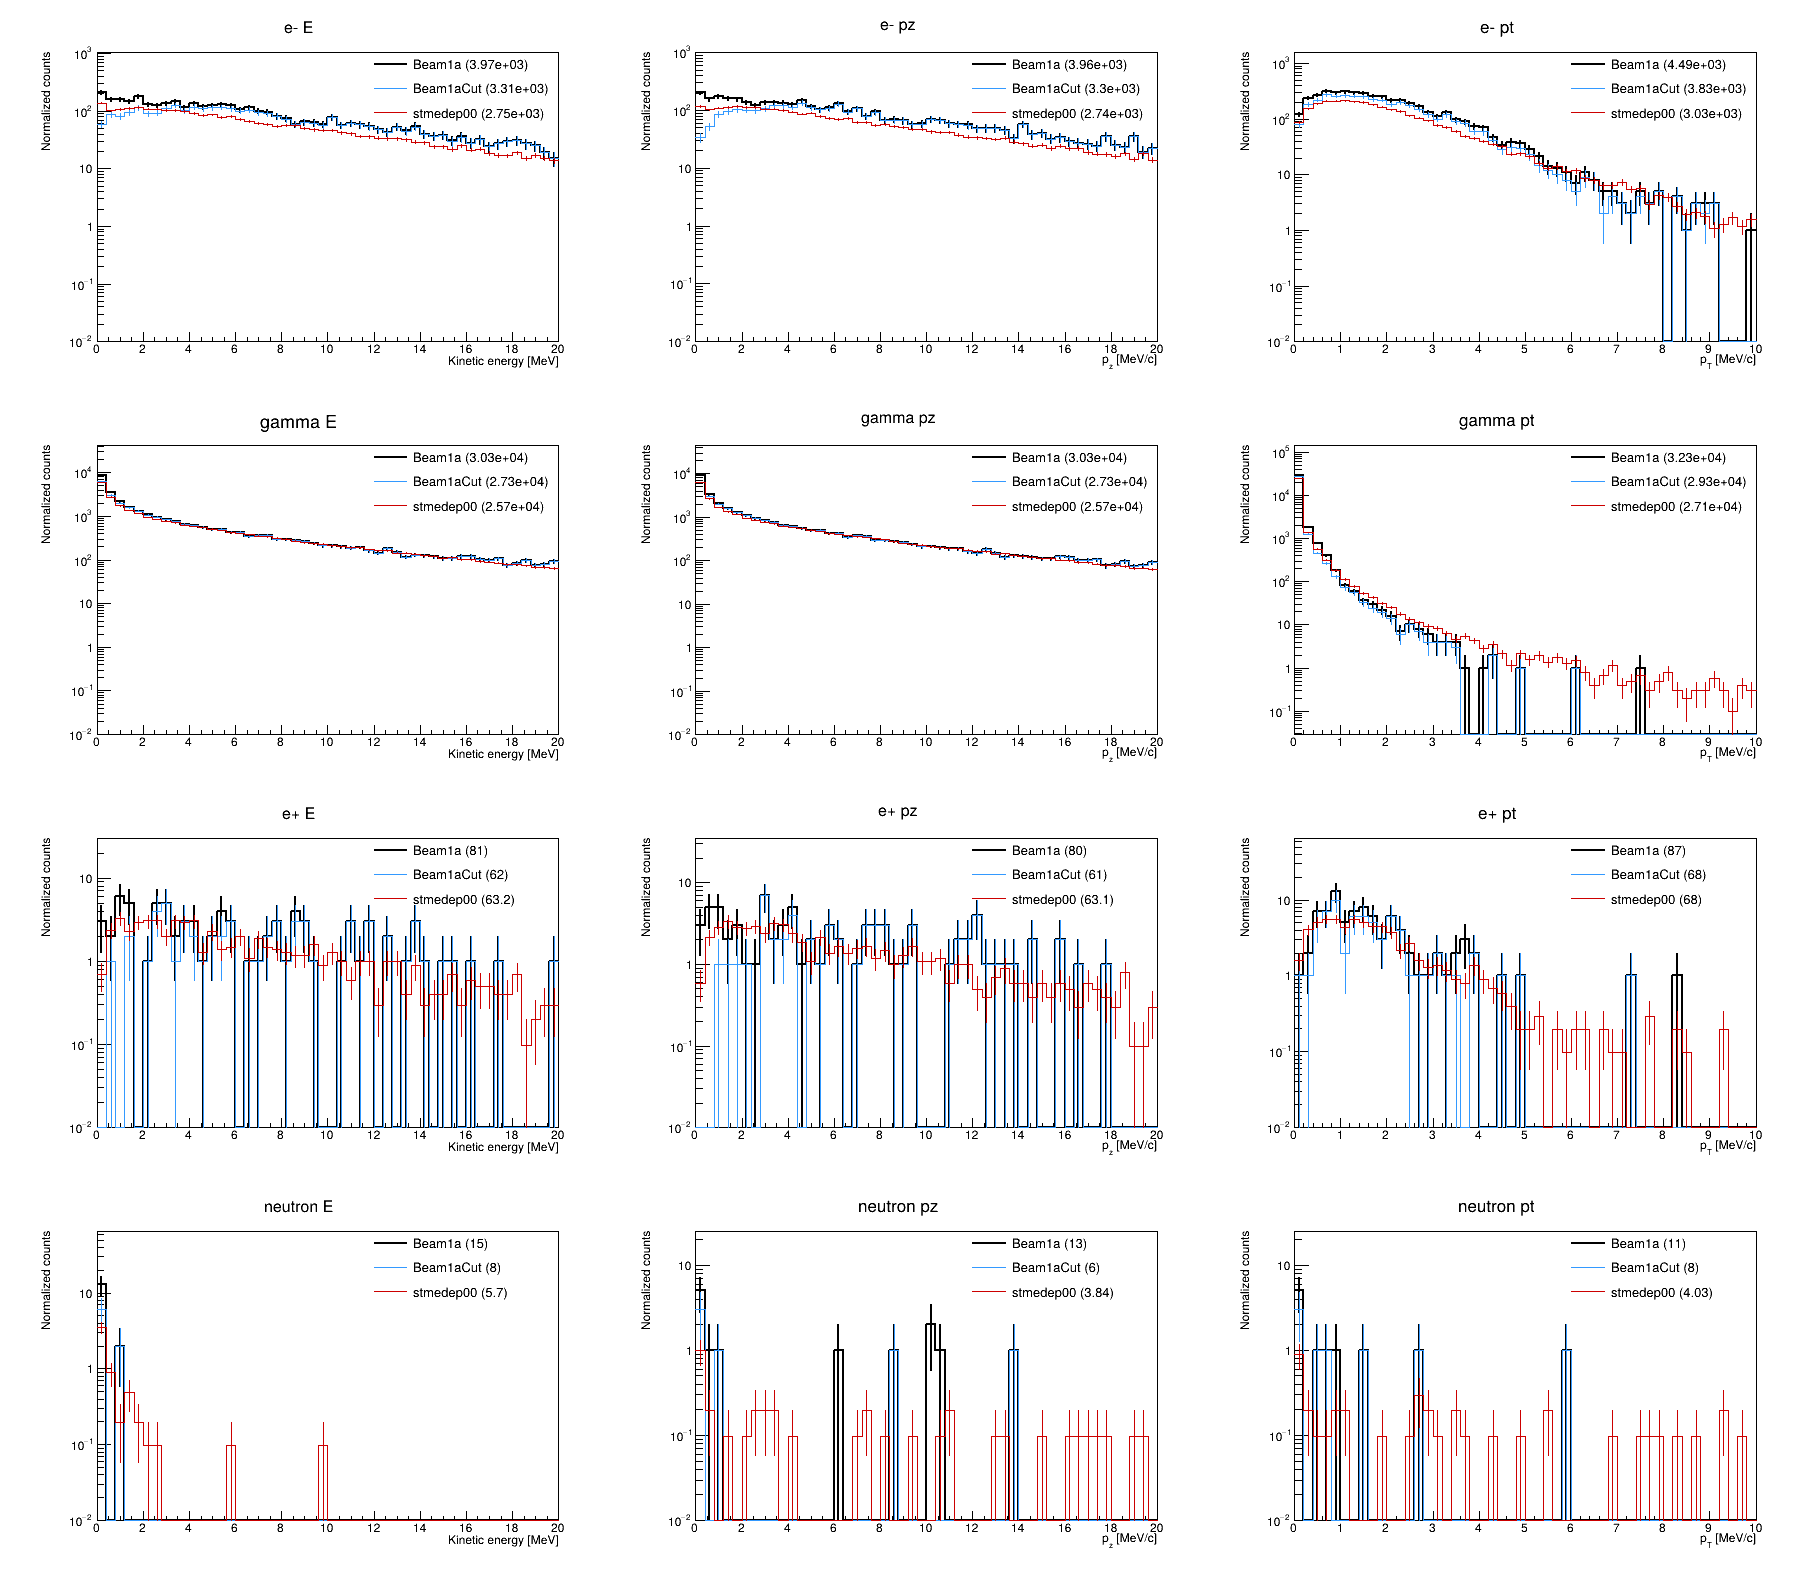

In [8]:
c = draw_spectra_comparison("Ele")
c.Draw()

Beam1a               e-              285        285
Beam1a               gamma          2705       2705
Beam1a               e+                6          6
Beam1a               neutron         454        454
---
Beam1aCut            e-              244        244
Beam1aCut            gamma          2390       2390
Beam1aCut            e+                5          5
Beam1aCut            neutron         330        330
---
stmedep00            e-              511        239
stmedep00            gamma          4370       2044
stmedep00            e+                6          3
stmedep00            neutron         232        109
---
stmedep01            e-              511        239
stmedep01            gamma          4369       2043
stmedep01            e+                6          3
stmedep01            neutron         233        109
---
stmedep02            e-              512        239
stmedep02            gamma          4369       2043
stmedep02            e+                6        

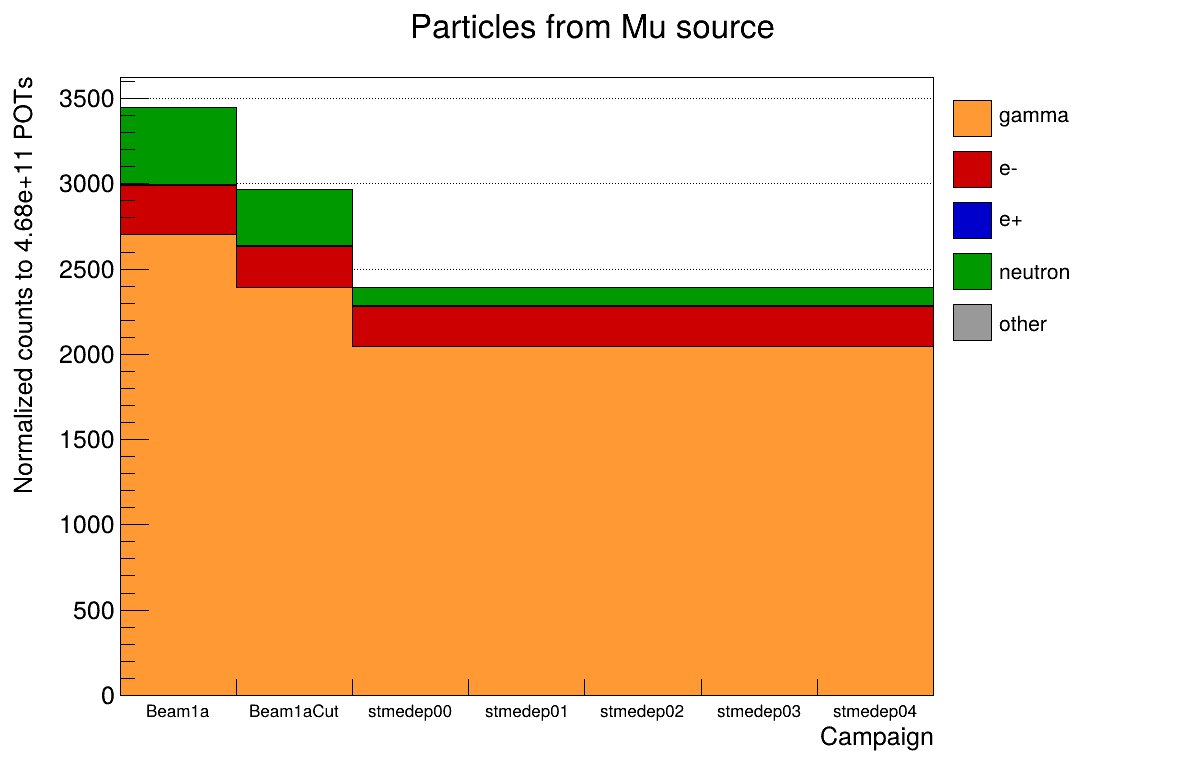

In [9]:
c = draw_pdg_composition("Mu")
c.Draw()

gamma: 2044/2705 = 0.76
e-: 239/285 = 0.84
neutron: 109/454 = 0.24
neutron flux seems to be have huge deficits due to ones come in at shallow angle. More on this later

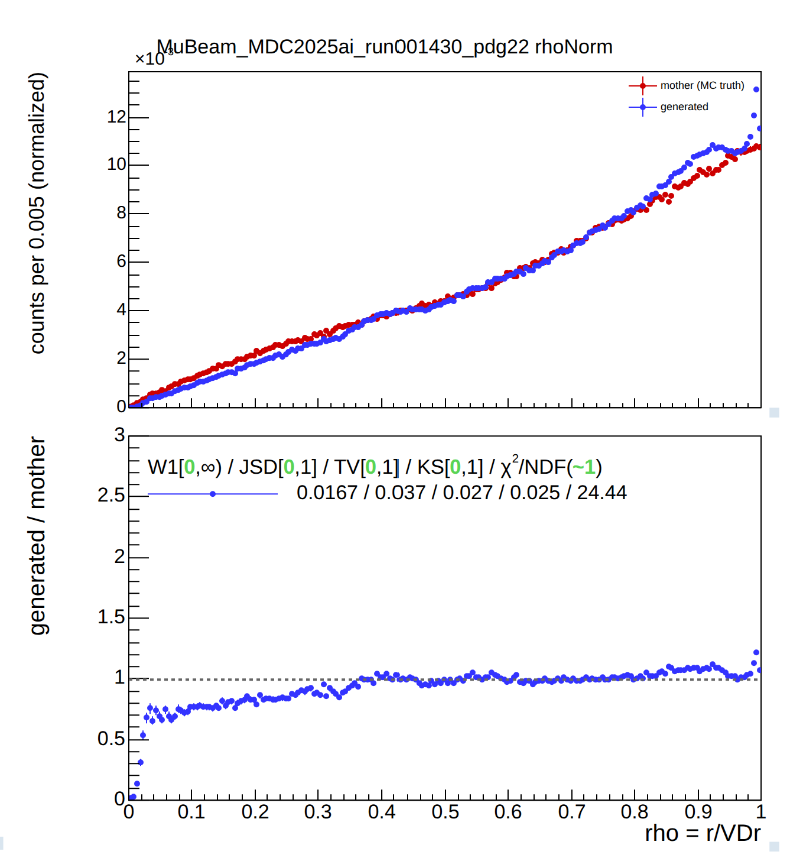
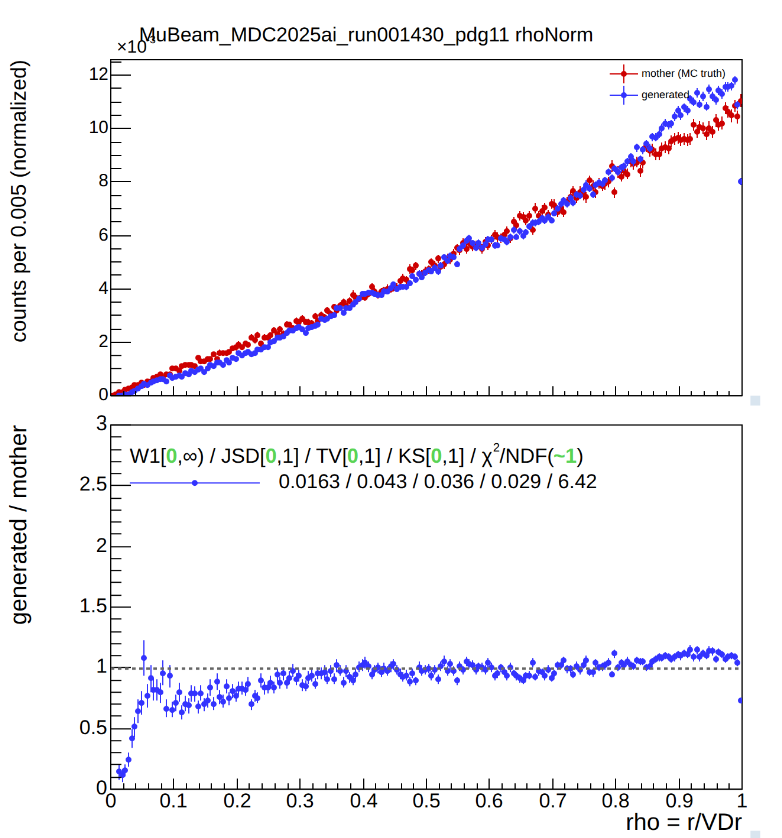
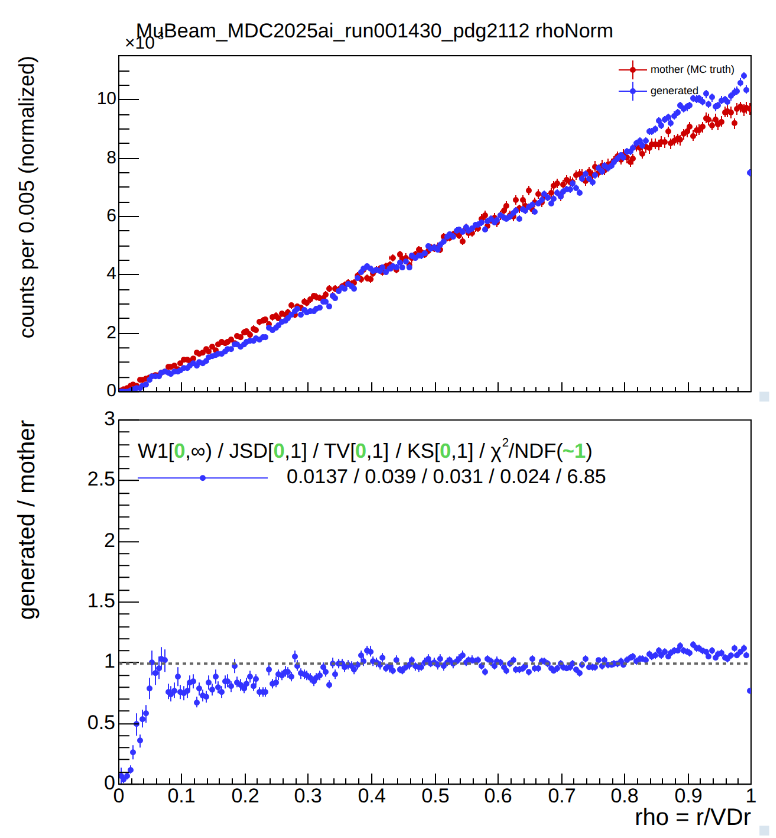

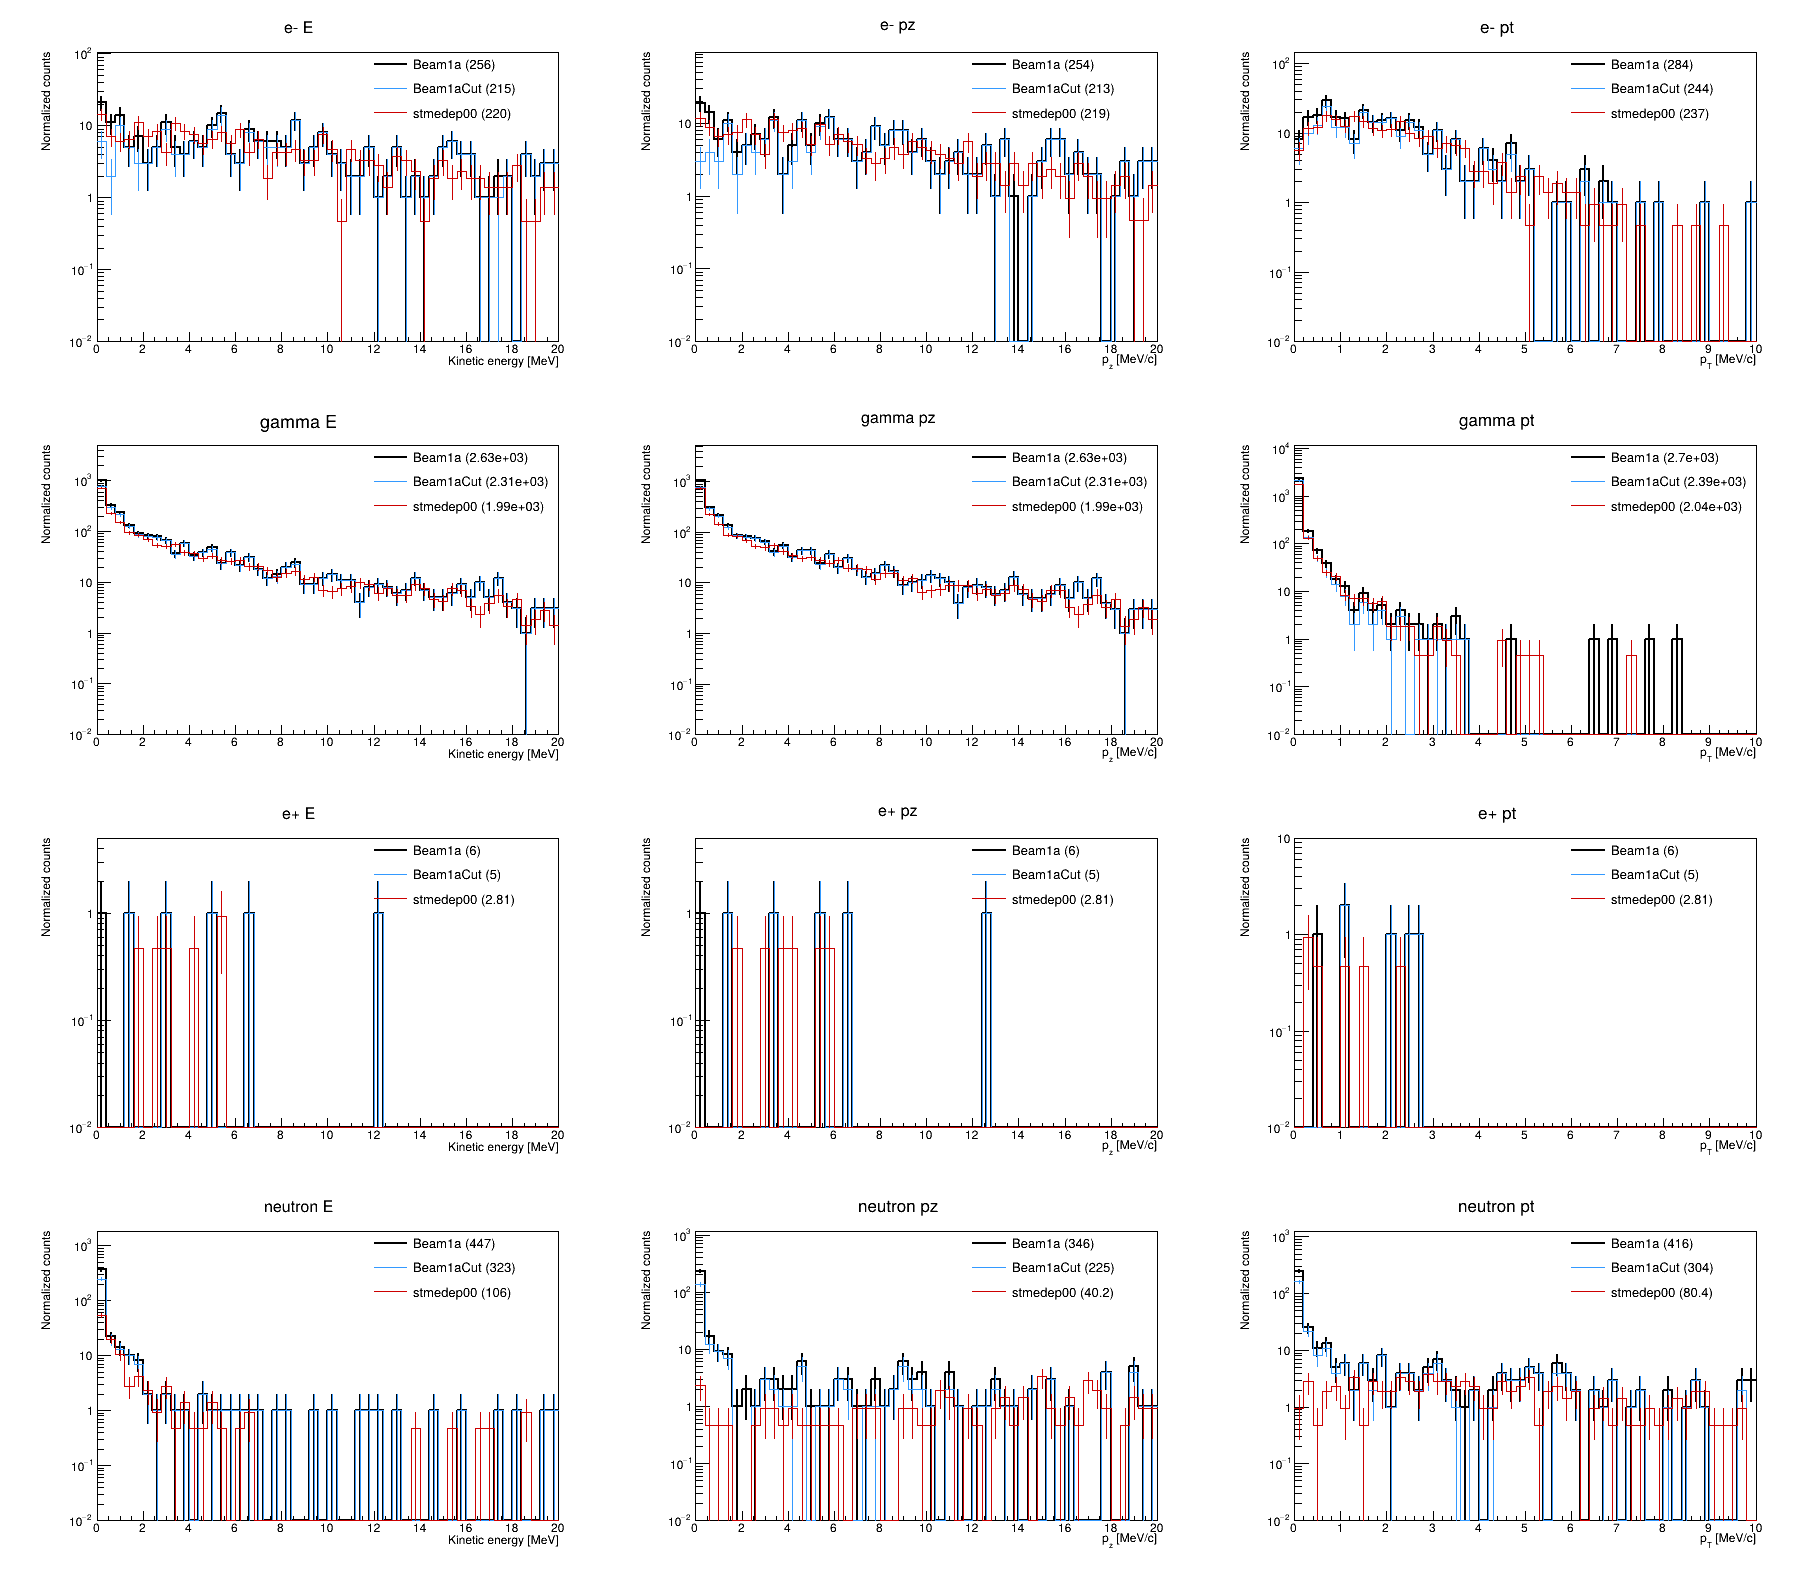

In [10]:
c = draw_spectra_comparison("Mu")
c.Draw()

Beam1a               e-                3          1
Beam1a               gamma           859        166
Beam1a               e+                0          0
Beam1a               neutron           0          0
---
Beam1aCut            e-                3          1
Beam1aCut            gamma           855        165
Beam1aCut            e+                0          0
Beam1aCut            neutron           0          0
---
stmedep00            e-                0          0
stmedep00            gamma           135        135
stmedep00            e+                0          0
stmedep00            neutron           0          0
---
stmedep01            e-                0          0
stmedep01            gamma           135        135
stmedep01            e+                0          0
stmedep01            neutron           0          0
---
stmedep02            e-                0          0
stmedep02            gamma           135        135
stmedep02            e+                0        

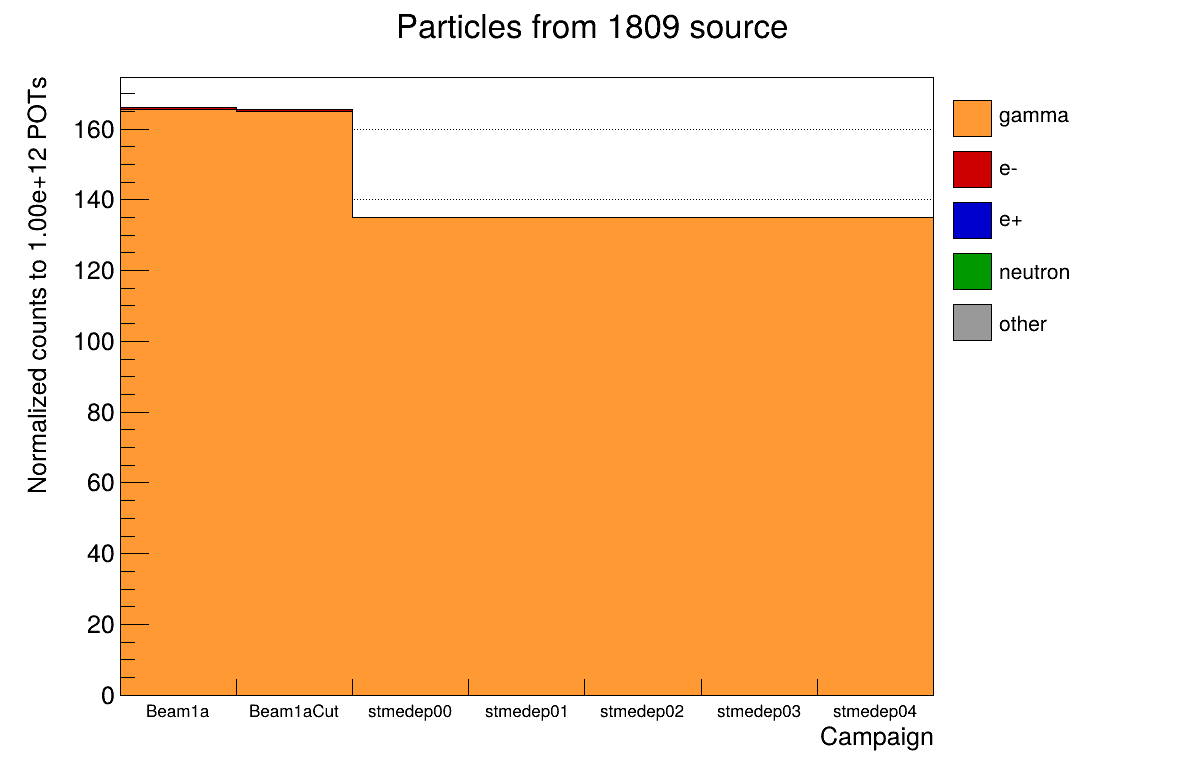

In [11]:
c = draw_pdg_composition("1809")
c.Draw()

gamma: 135/166 = 0.81
Likely stat fluctuations + better center needed. Comparing the central region the smaller sample seems to have fewer events at VD116
20k vs 6122 events

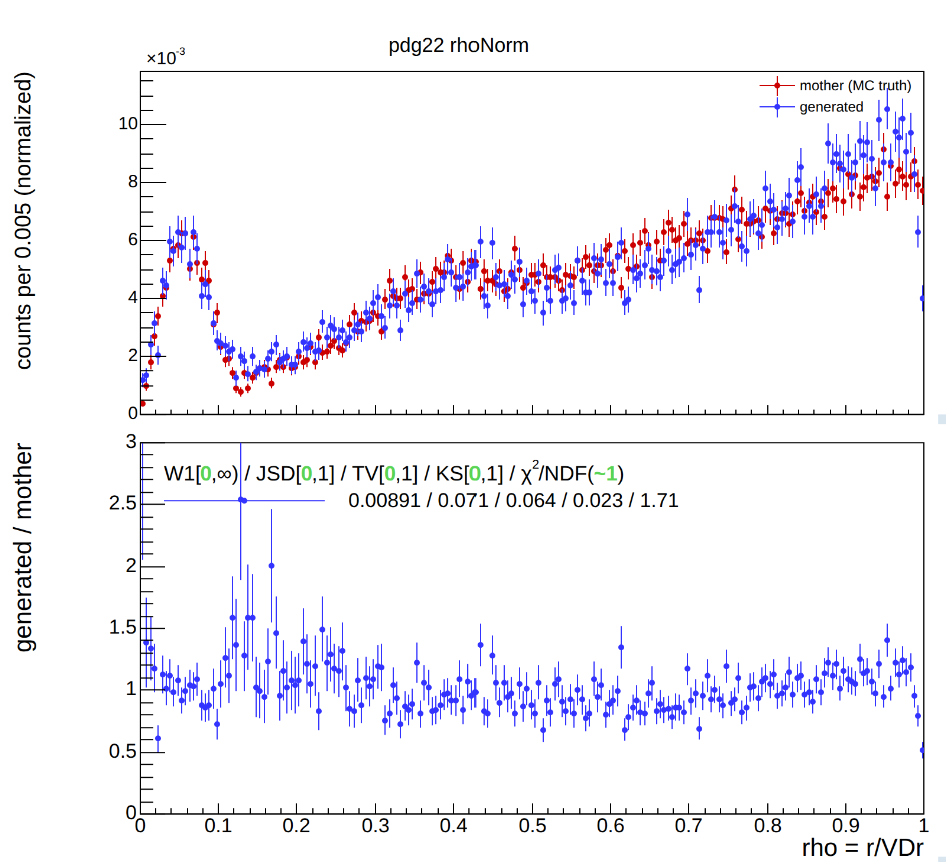
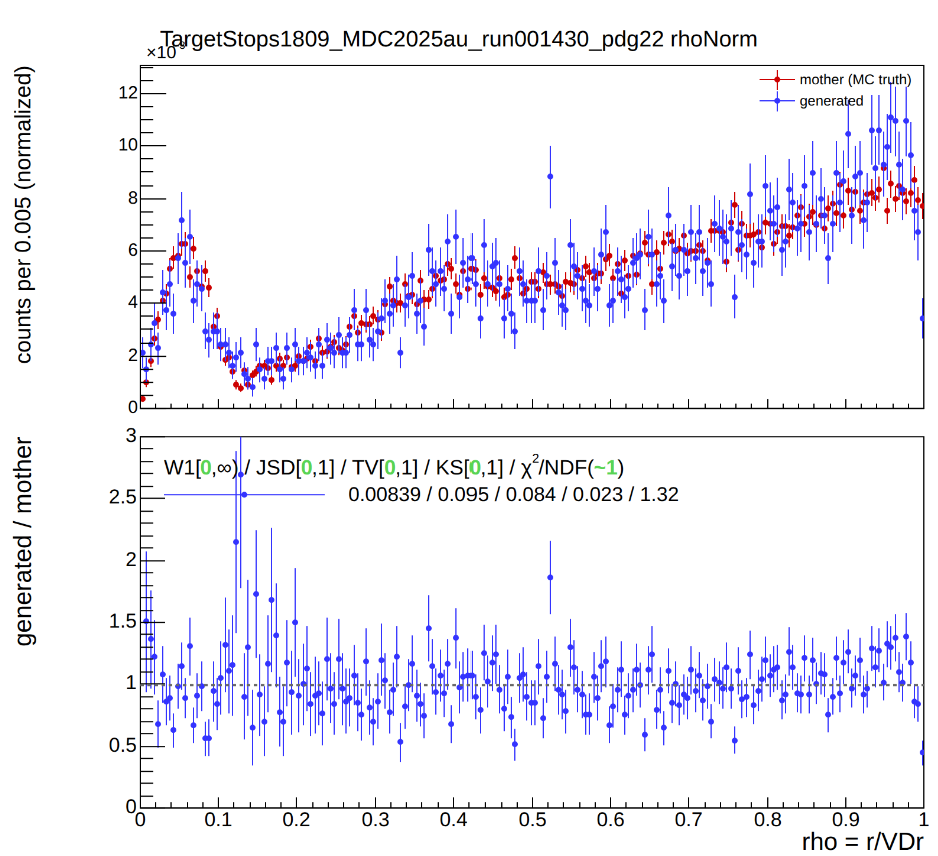

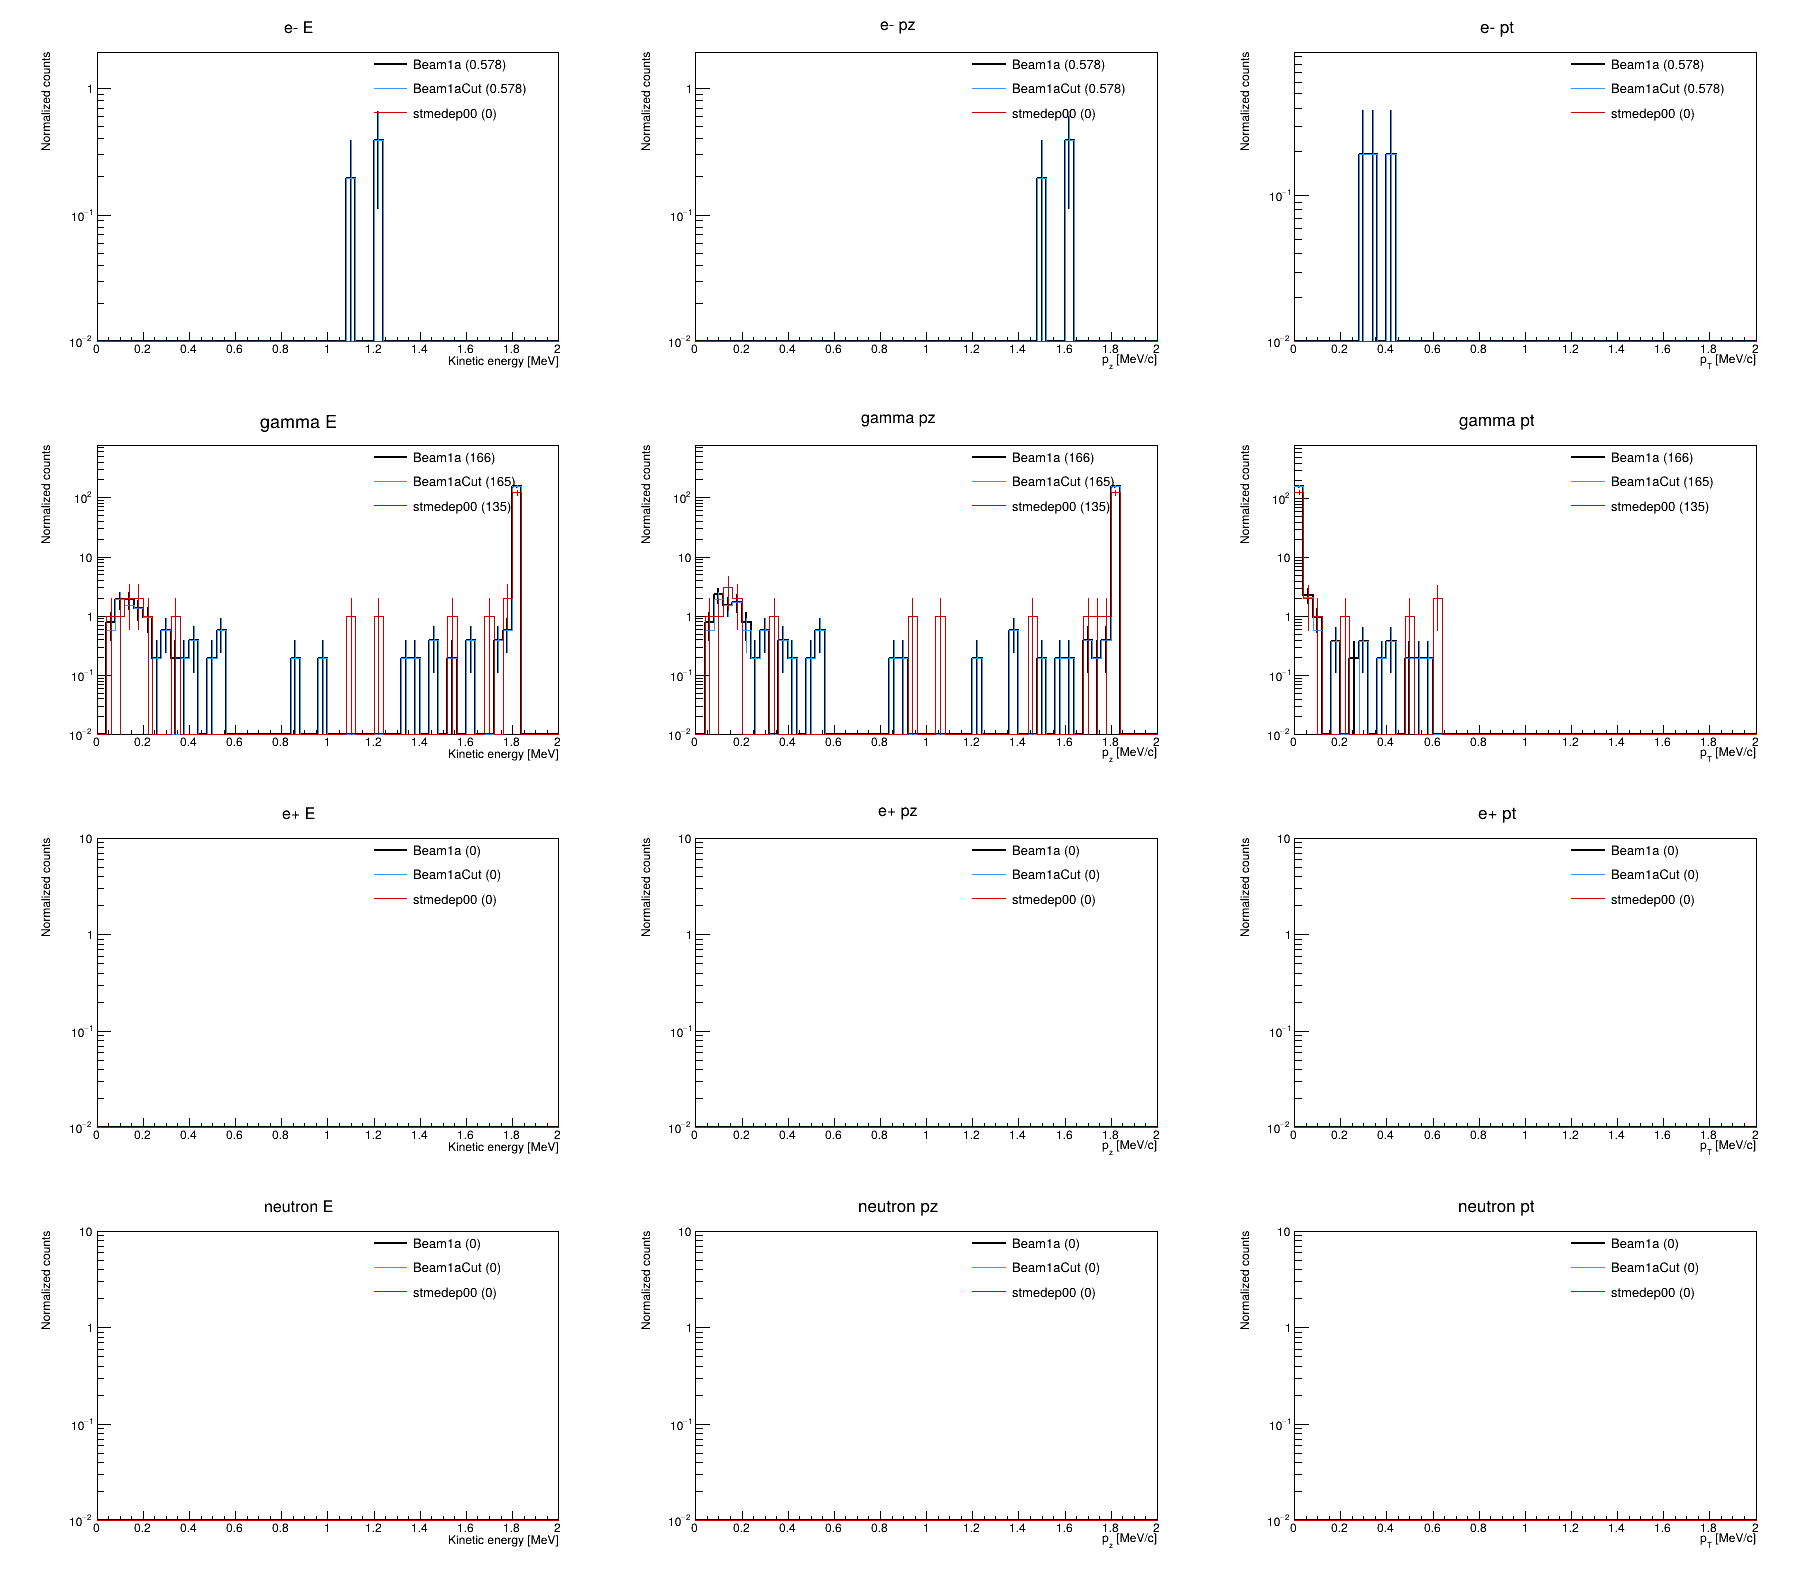

In [12]:
c = draw_spectra_comparison("1809", ranges={"E": (0., 2.), "pz": (0., 2.), "pt": (0., 2.)})
c.Draw()

Beam1a               e-                0          0
Beam1a               gamma            24         24
Beam1a               e+                0          0
Beam1a               neutron          35         35
---
Beam1aCut            e-                0          0
Beam1aCut            gamma            21         21
Beam1aCut            e+                0          0
Beam1aCut            neutron          23         23
---
stmedep00            e-               76          0
stmedep00            gamma          8127         30
stmedep00            e+                5          0
stmedep00            neutron        2519          9
---
stmedep01            e-               76          0
stmedep01            gamma          8127         30
stmedep01            e+                5          0
stmedep01            neutron        2522          9
---
stmedep02            e-               76          0
stmedep02            gamma          8126         30
stmedep02            e+                5        

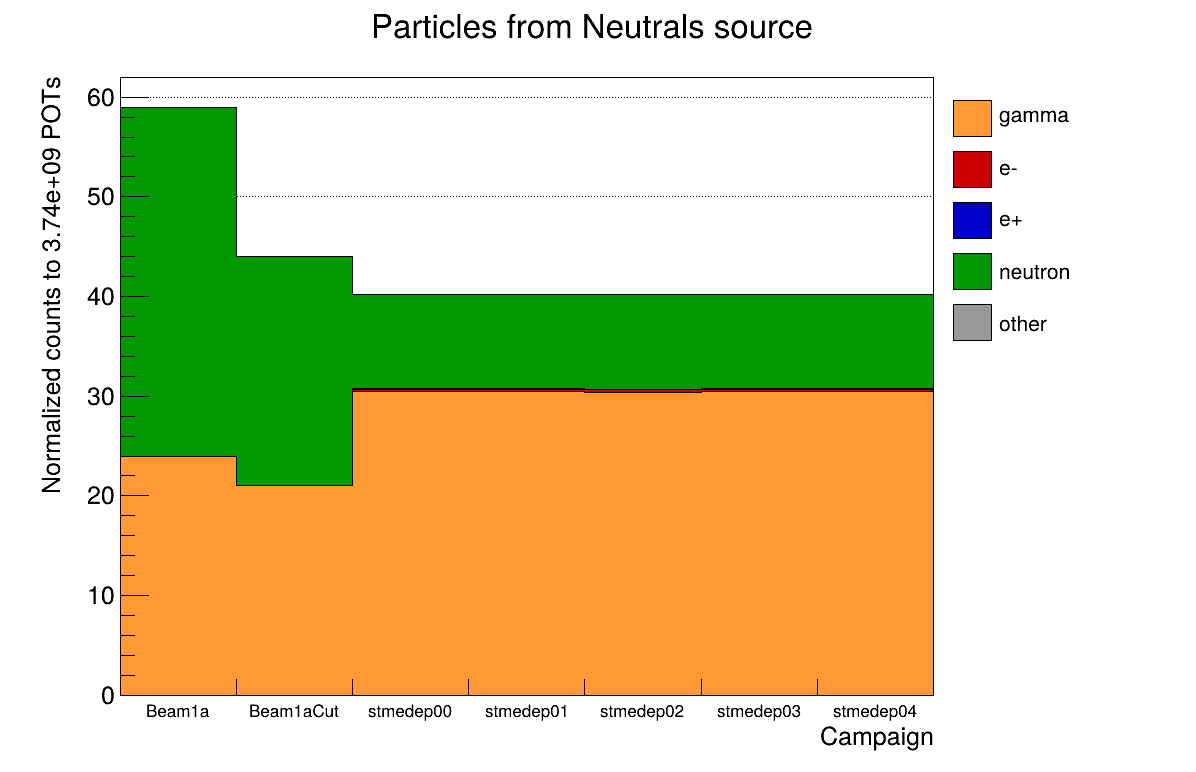

In [13]:
c = draw_pdg_composition("Neutrals")
c.Draw()

gamma: difference seems highly statistical
neutrons: 9/35 = 0.26 
No obvious offset in VD116 fitting / generation

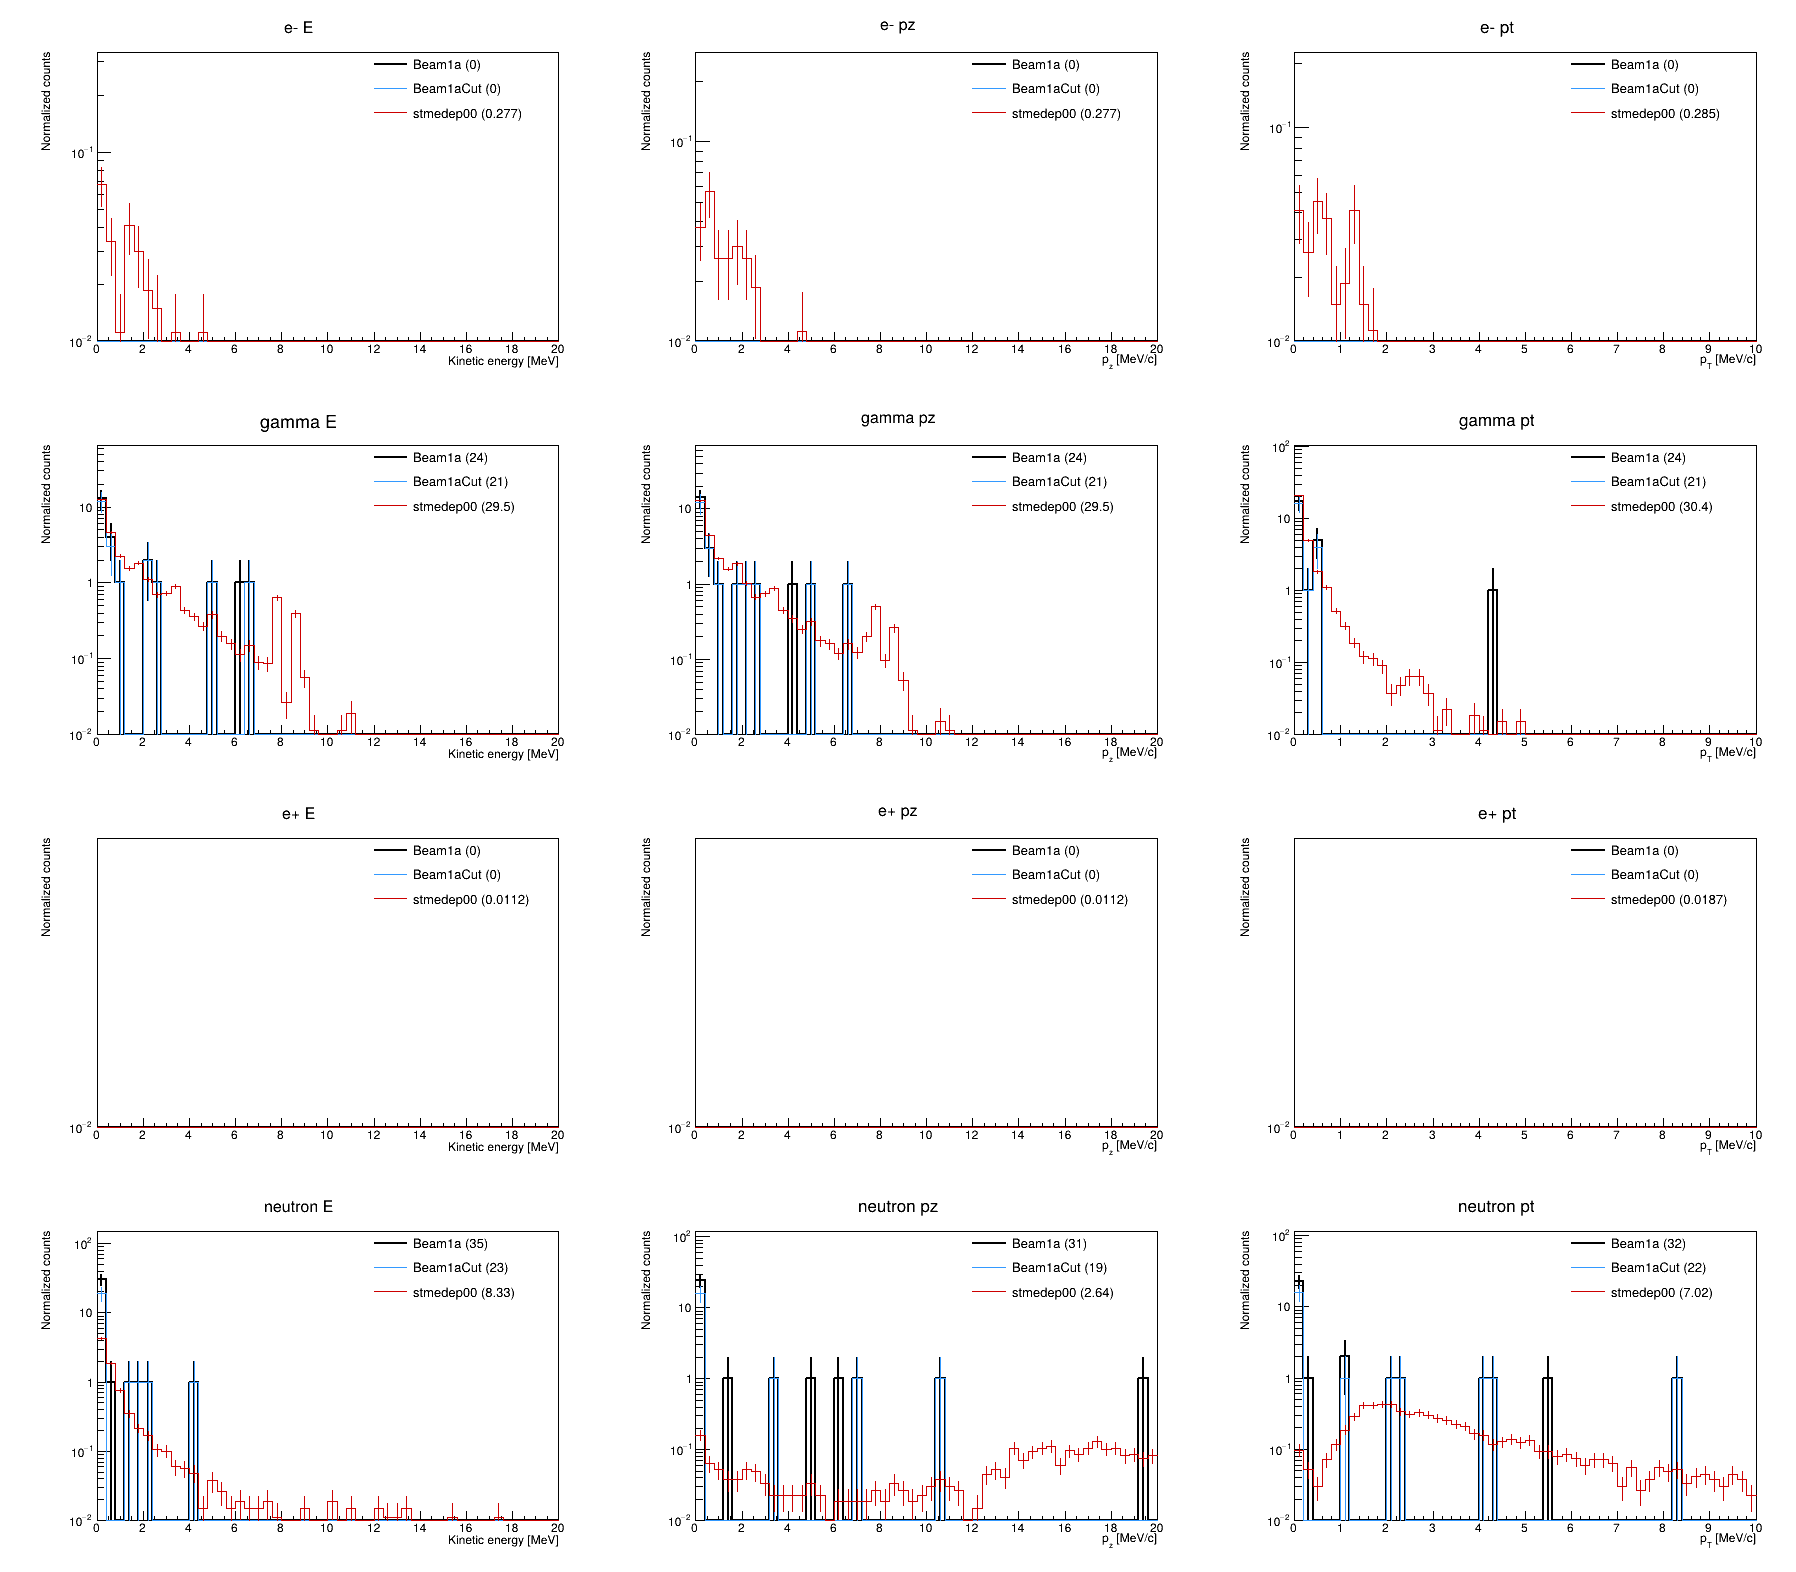

In [14]:
c = draw_spectra_comparison("Neutrals")
c.Draw()

In [15]:
def draw_pz_vs_pt(category,
                  campaigns=("Beam1a", "Beam1aCut", "stmedep00"),
                  nbins_pz=50, nbins_pt=50,
                  pz_range=(0., 20.), pt_range=(0., 10.),
                  logz=True):
    """2D pz vs pt per species, one column per campaign. Returns the canvas."""

    species = list(pdg_groups.keys())          # e-, gamma, e+, neutron

    hist_dict = {}   # (campaign, species) -> TH2D

    for campaign in campaigns:
        is_cut = campaign.endswith("Cut")
        base_campaign = campaign[:-3] if is_cut else campaign
        sample = f"{category}_{base_campaign}"

        if sample not in sample_groups[category]:
            print(f"Missing sample: {sample}")
            continue

        df = (ROOT.RDataFrame("Stage1virtualdetector/ttree",
                              sample_groups[category][sample]["file"])
              .Filter("pz > 0")
              .Define("pt", "sqrt(px*px + py*py)"))
        if is_cut:
            df = df.Filter(BEAM1ACUT_EXPR)

        weight = norm_weights[sample]

        booked = {}
        for sp in species:
            name = f"h2_{category}_{campaign}_{sp}"
            booked[sp] = (df.Filter(f"pdgId == {pdg_groups[sp]}")
                            .Histo2D((name, "", nbins_pt, *pt_range,
                                            nbins_pz, *pz_range),
                                     "pt", "pz"))

        for sp, ptr in booked.items():
            h = ptr.GetValue().Clone()
            h.SetDirectory(0)
            ROOT.SetOwnership(h, False)
            h.Scale(weight)
            h.SetTitle(f"{campaign} #minus {sp};p_{{T}} [MeV/c];p_{{z}} [MeV/c]")
            hist_dict[(campaign, sp)] = h

    # ------------------------------------
    # draw: rows = species, columns = campaigns
    # ------------------------------------
    ncol = len(campaigns)
    c = ROOT.TCanvas(f"c_pzpt_{category}", f"{category} pz vs pt",
                     700 * ncol, 600 * len(species))
    c.Divide(ncol, len(species))

    for irow, sp in enumerate(species):

        # common z scale across campaigns so the columns are comparable
        present = [cp for cp in campaigns if (cp, sp) in hist_dict]
        if not present:
            continue
        zmax = max(hist_dict[(cp, sp)].GetMaximum() for cp in present)
        zmin = min(h for h in
                   (hist_dict[(cp, sp)].GetMinimum(0) for cp in present)
                   if h > 0) if logz else 0.

        for icol, cp in enumerate(campaigns):
            pad = c.cd(irow * ncol + icol + 1)
            pad.SetRightMargin(0.16)      # room for the COLZ palette
            pad.SetLeftMargin(0.13)
            if logz:
                pad.SetLogz()

            if (cp, sp) not in hist_dict:
                continue
            h = hist_dict[(cp, sp)]
            h.GetZaxis().SetRangeUser(zmin, zmax)
            h.GetYaxis().SetTitleOffset(1.5)
            h.Draw("colz")
            pad.Update()                      # stats object is created here
            st = h.FindObject("stats")
            if st:
                st.SetX1NDC(0.60); st.SetX2NDC(0.82)
                st.SetY1NDC(0.72); st.SetY2NDC(0.90)

    c._keep = hist_dict
    c.Modified()
    c.Update()

    return c

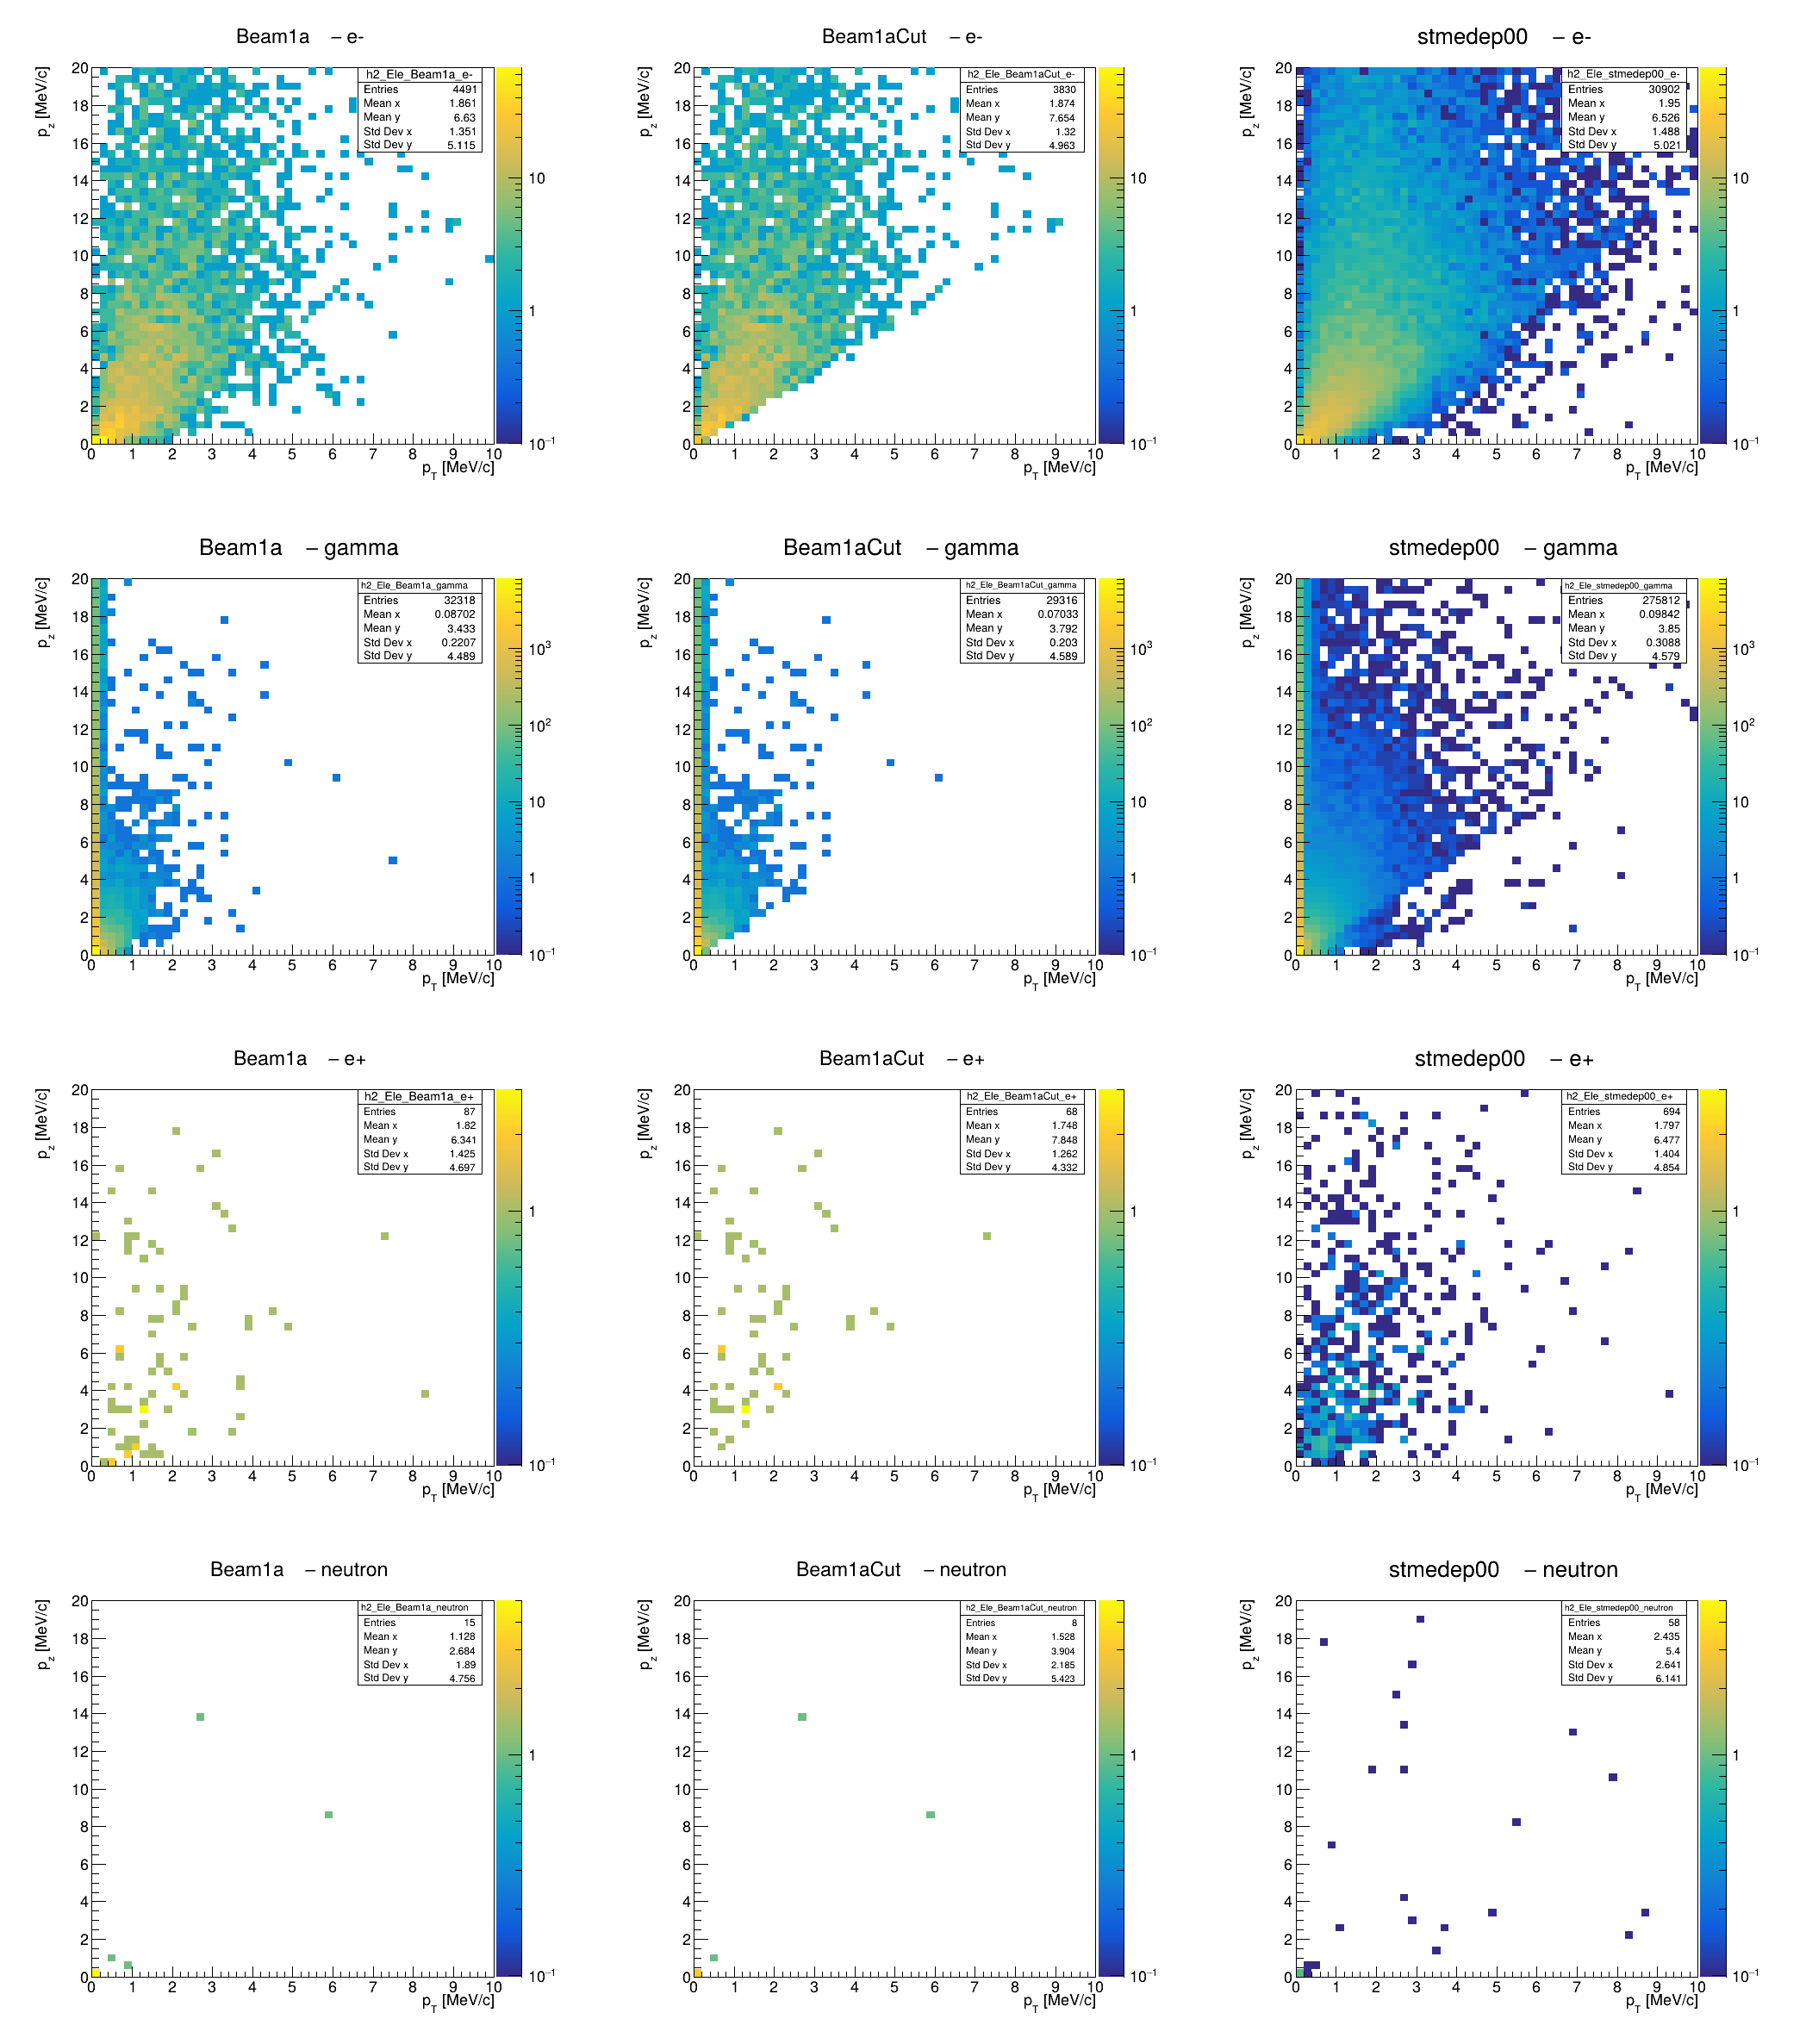

In [16]:
c = draw_pz_vs_pt("Ele")
c.Draw()

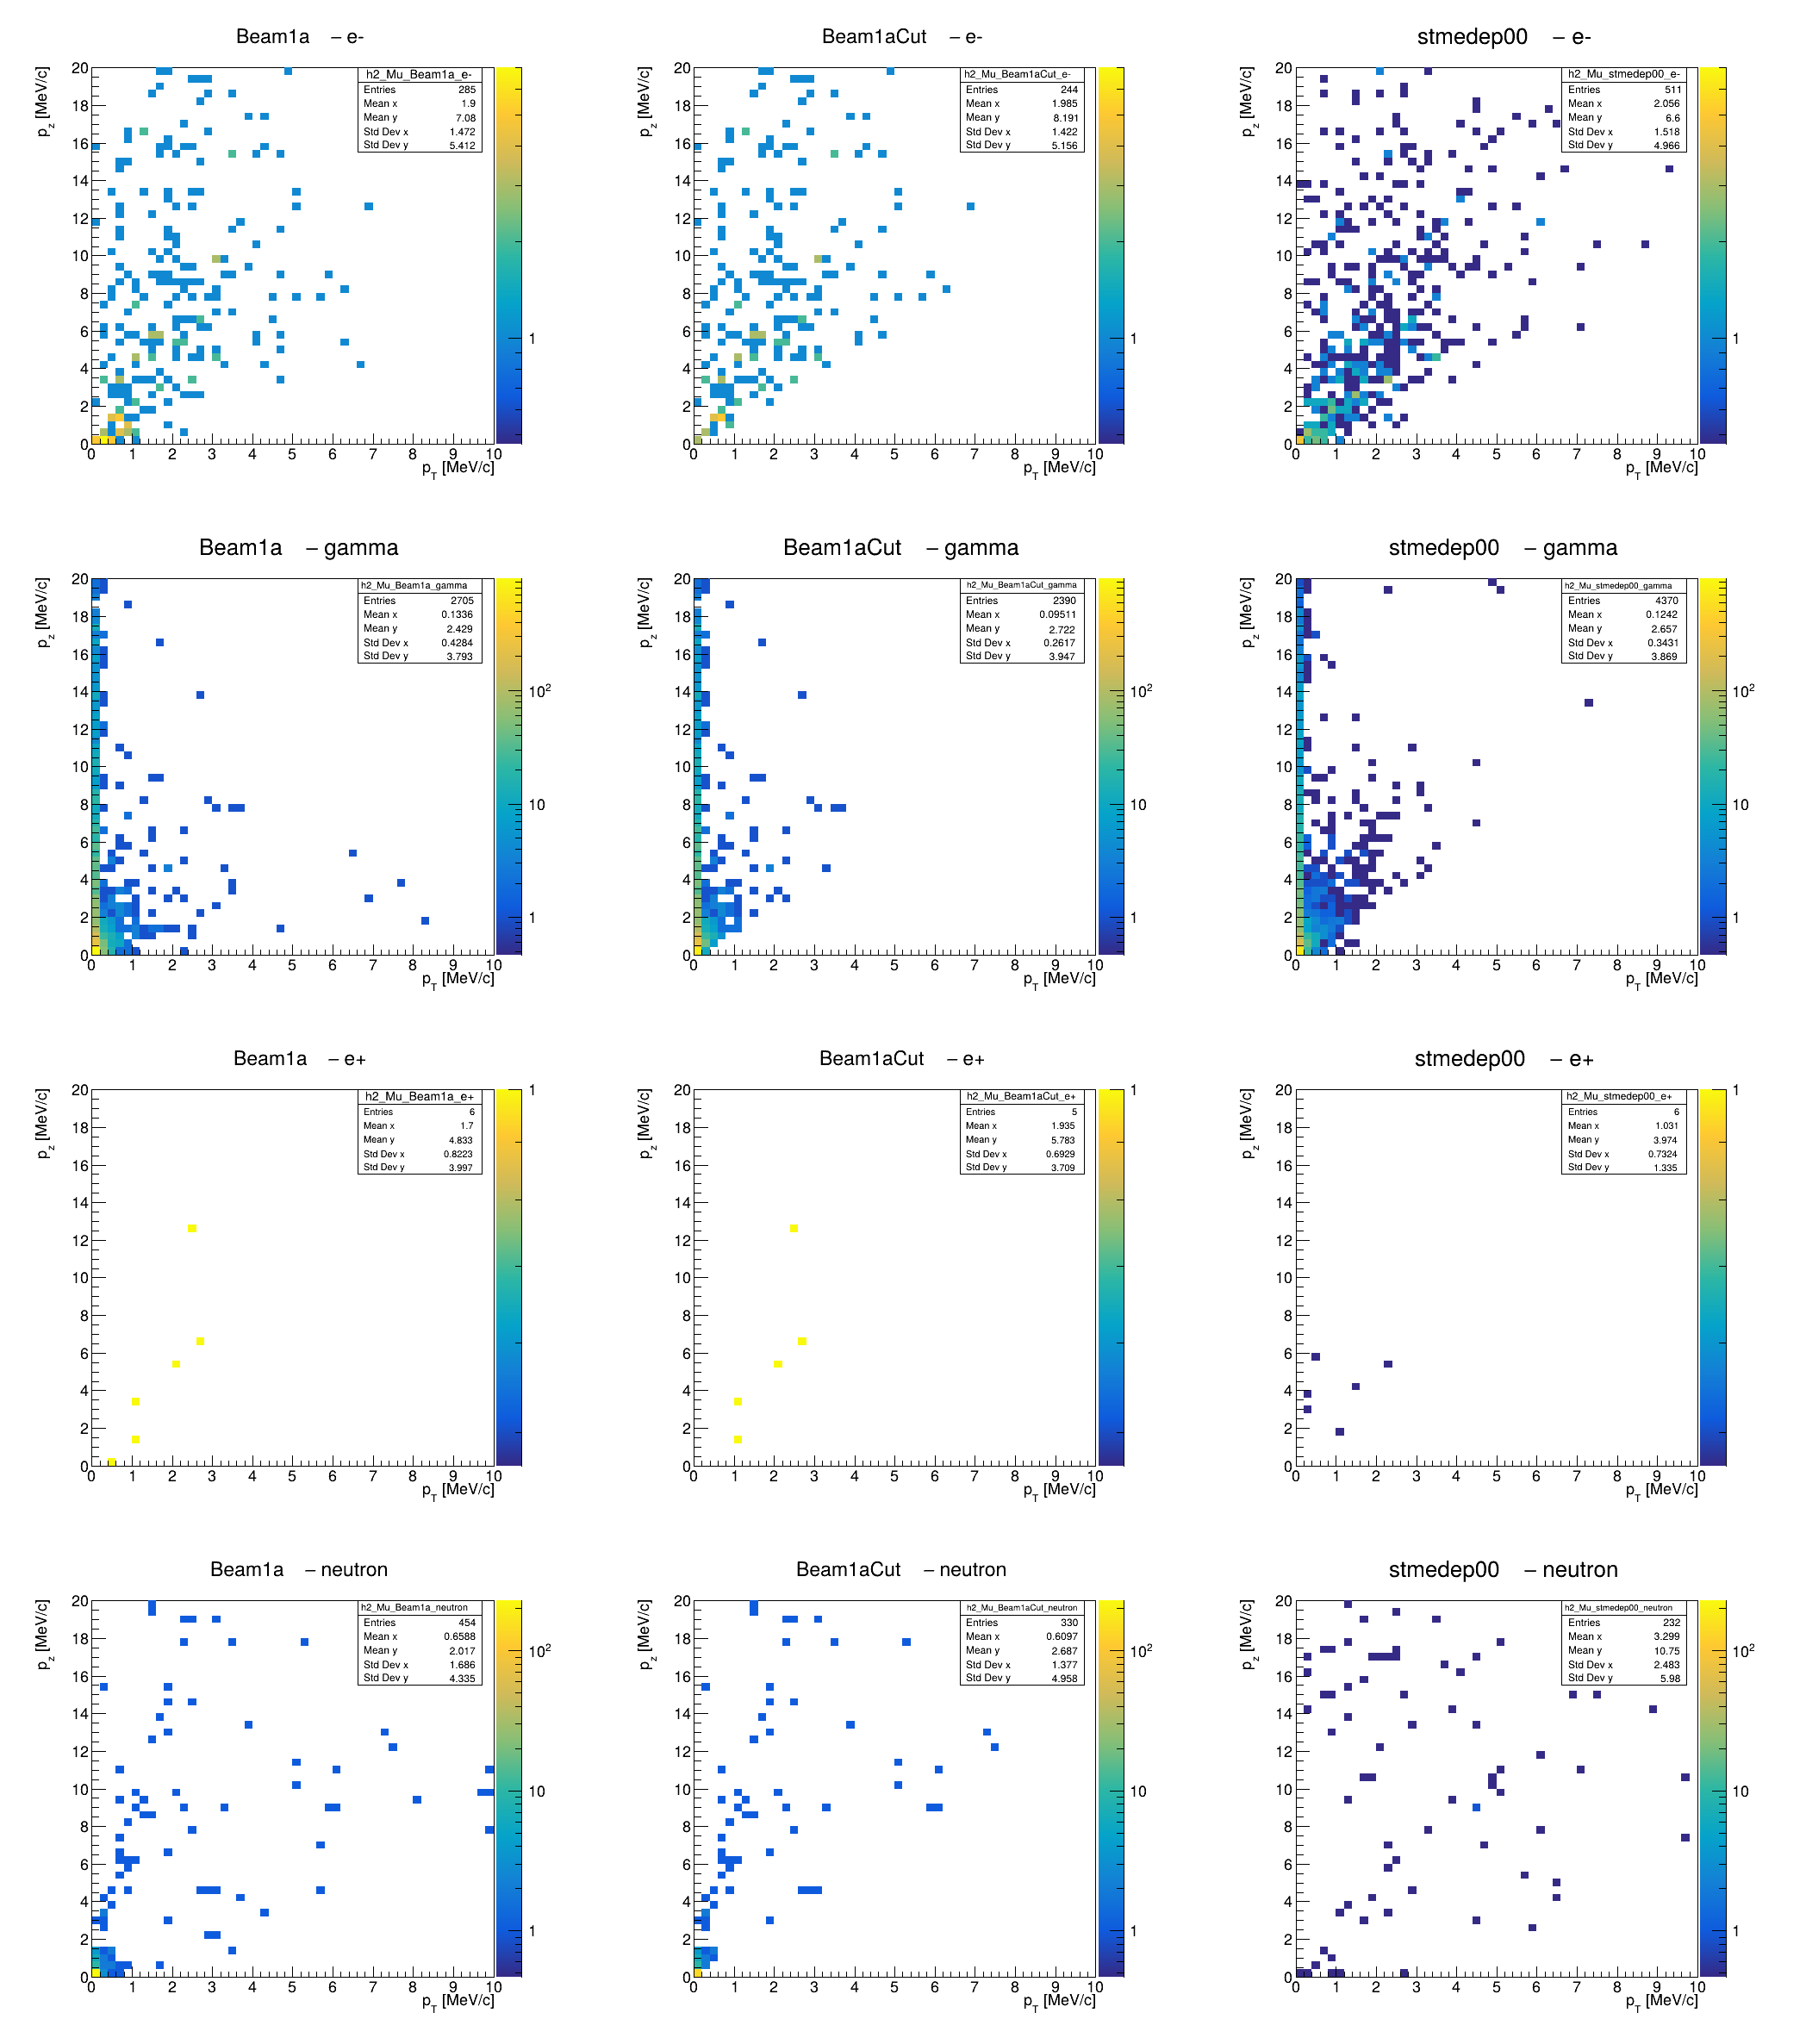

In [17]:
c = draw_pz_vs_pt("Mu")
c.Draw()

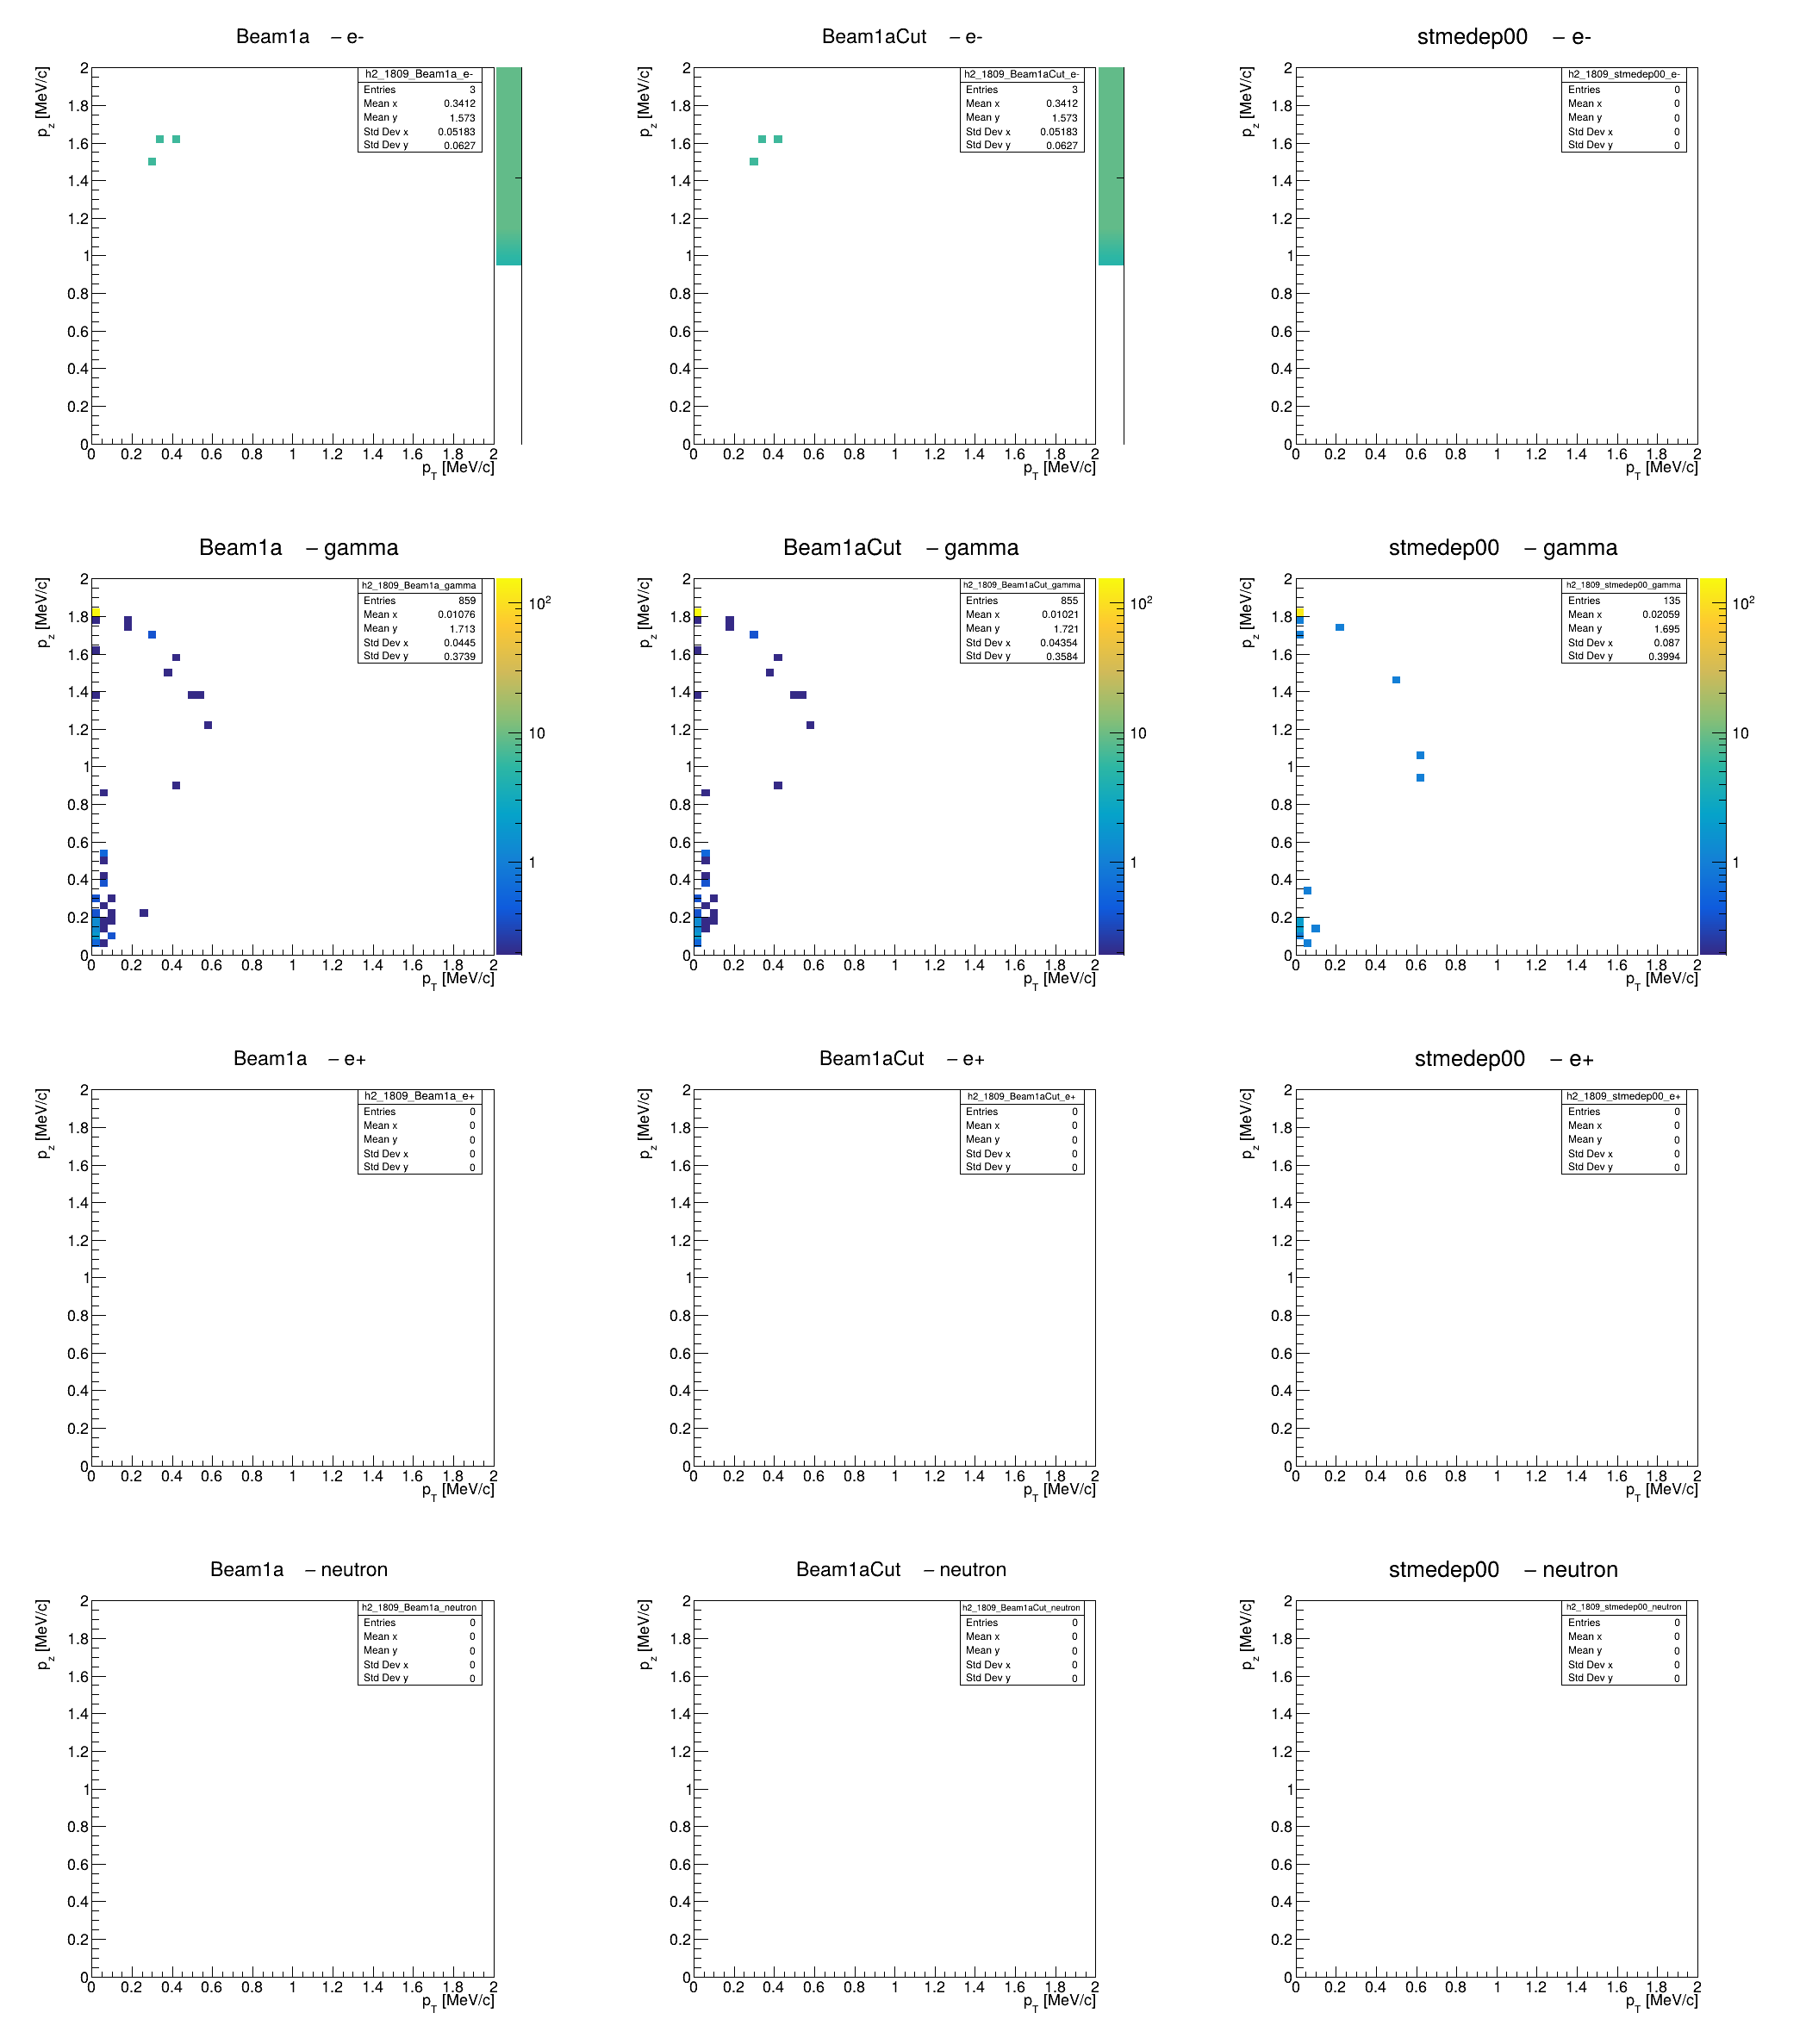

In [18]:
c = draw_pz_vs_pt("1809", pz_range=(0., 2.), pt_range=(0., 2.))
c.Draw()

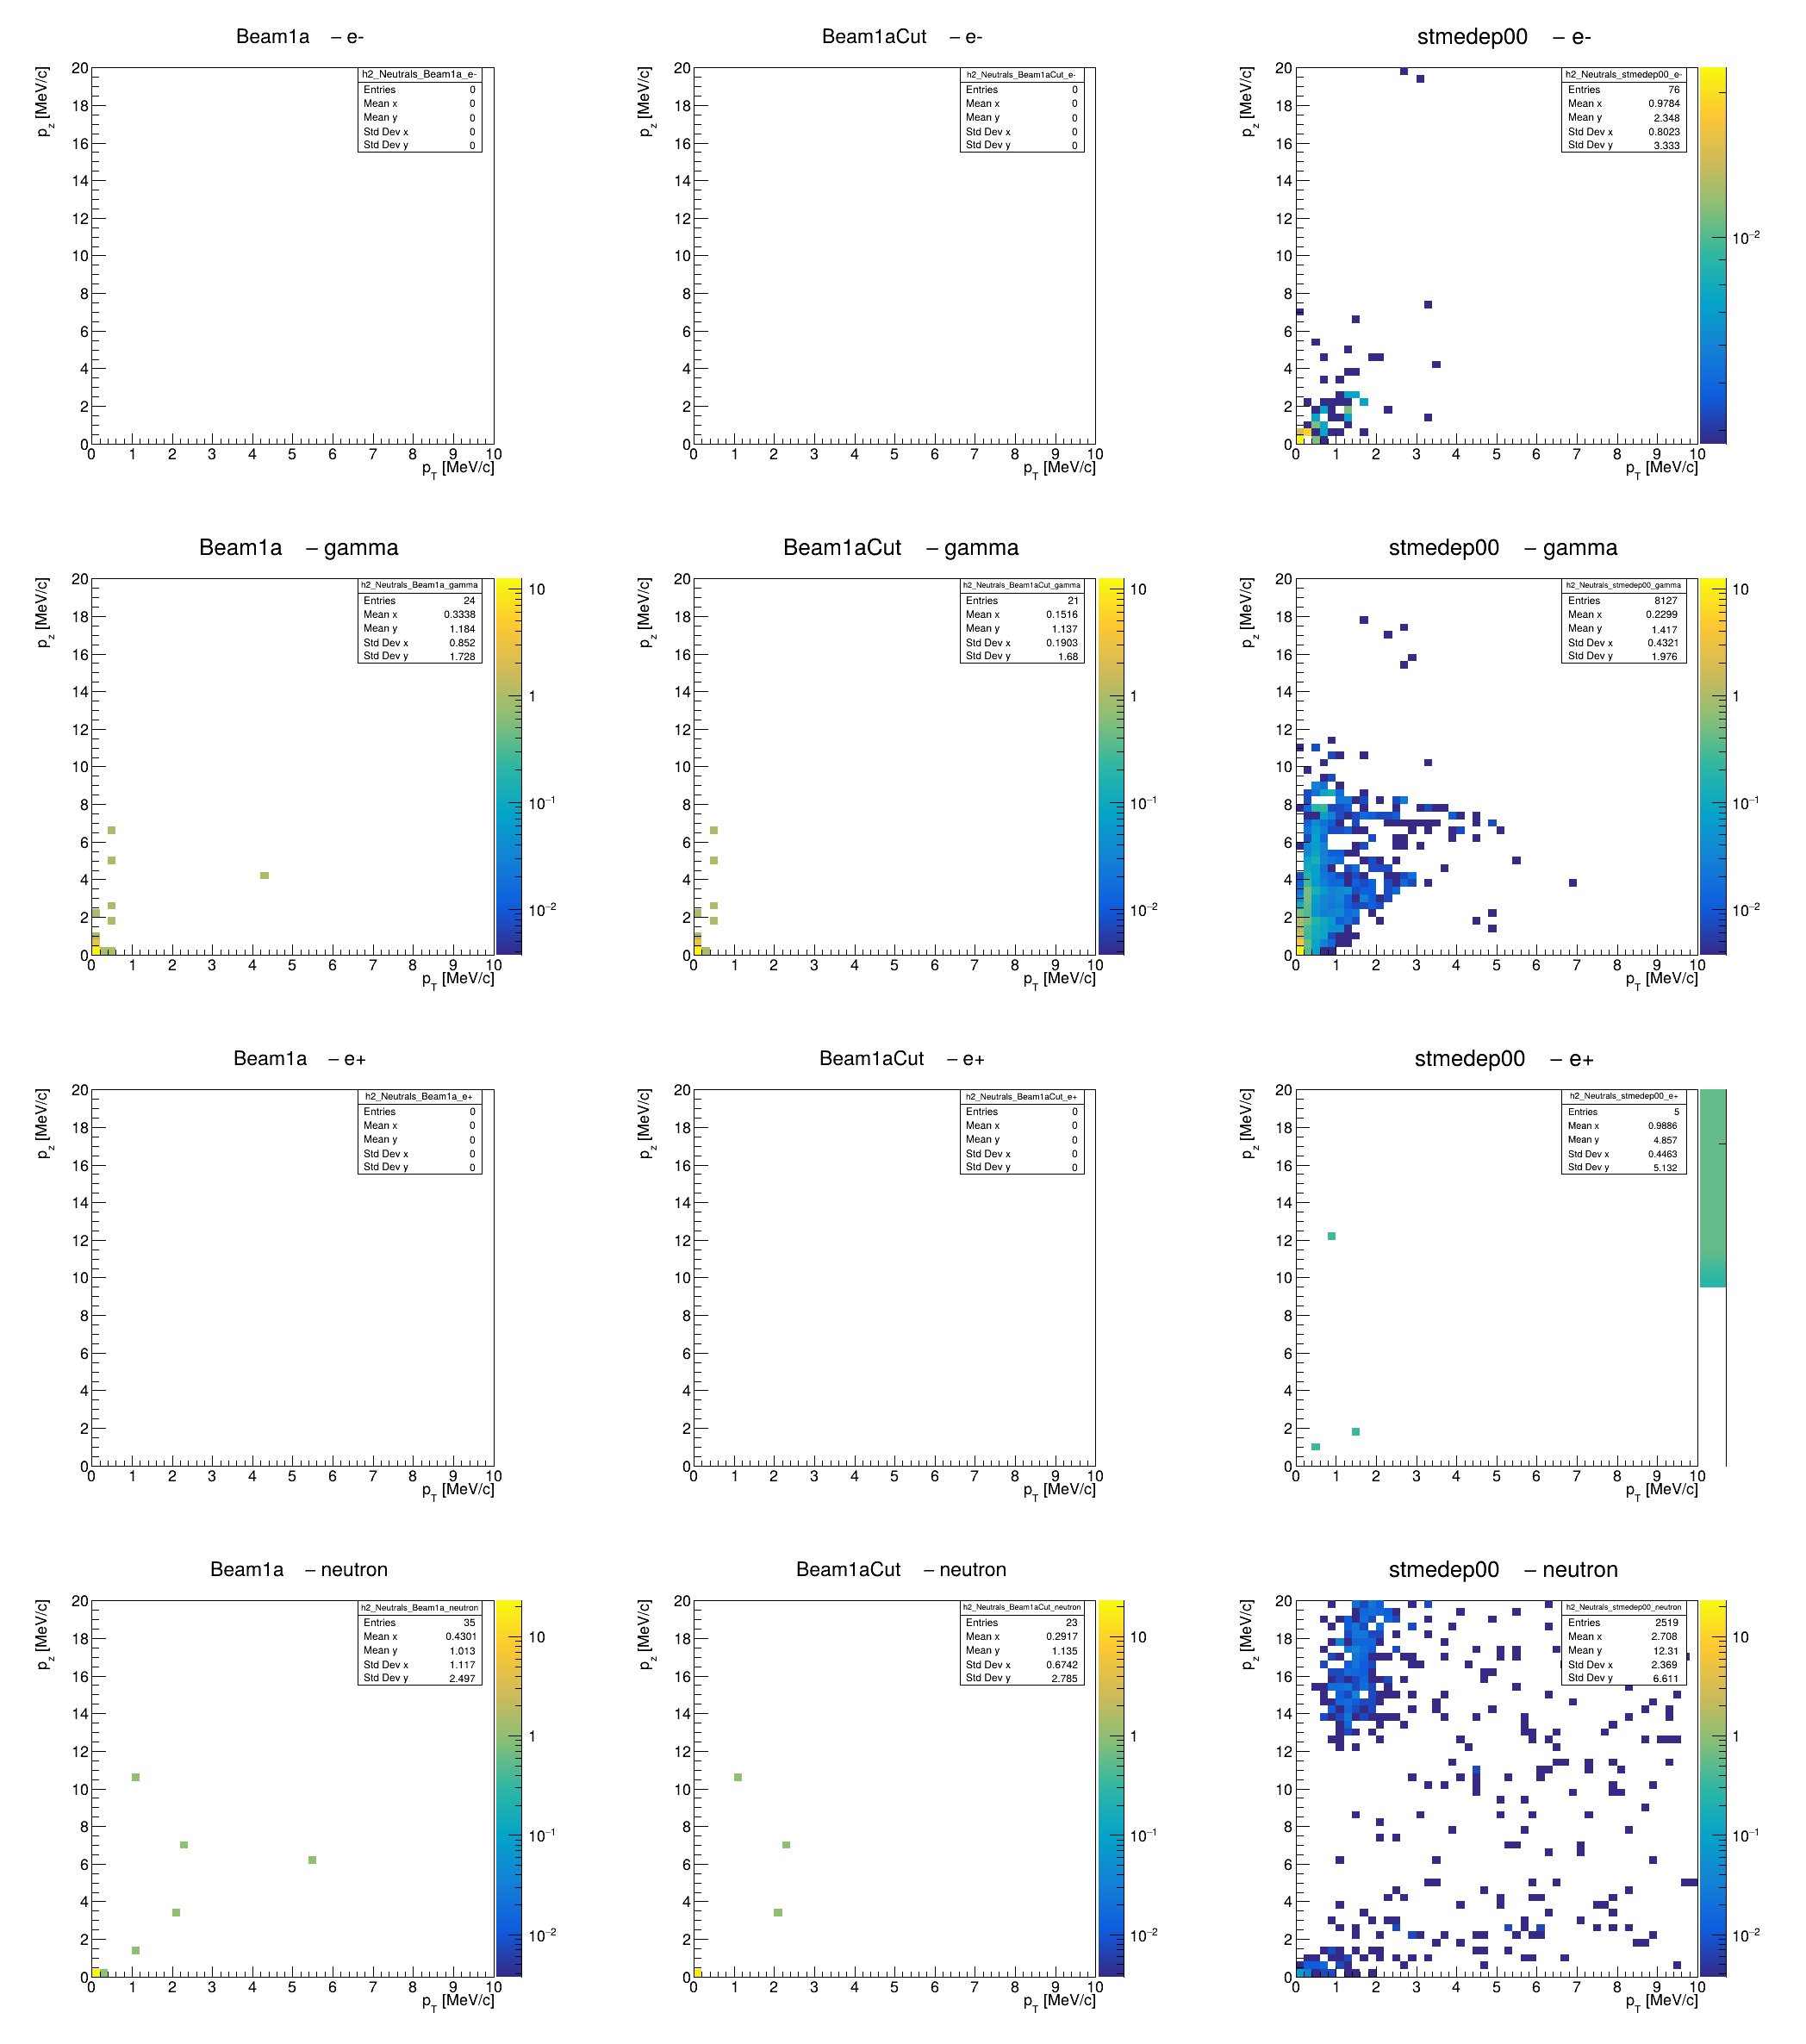

In [19]:
c = draw_pz_vs_pt("Neutrals")
c.Draw()